# Intermitência severa (severe slugging) com o modelo de redes

Pergunta em aberto da tese: o modelo a dois fluidos a 4 equações, resolvido
pelo método das linhas com integrador implícito, consegue reproduzir a
intermitência severa numa geometria linha–riser (trecho horizontal, trecho
**descendente**, **riser** vertical e trecho horizontal até o separador)?

## O que foi mudado em relação à tese

1. **Discretização.** Galerkin/diferenças centrais não têm dissipação nas ondas
   de fração de área (modelo não hiperbólico) e o "upwind" original era diferença
   regressiva em todas as variáveis, inclusive a pressão. Aqui usa-se o esquema de
   **volumes finitos escalonados** (`fv_upwind`): balanços de massa exatos por
   célula, convecção de momento *donor cell* pela velocidade de cada fase
   (chaveamento suave, largura adaptativa às vazões locais) e gradiente de pressão
   centrado entre células.
2. **Fases que desaparecem.** Os coeficientes das equações de massa usam a fração
   de gás real da célula: quando ela vai a zero, a compressibilidade do gás some e a
   acumulação de líquido vai para a pressão (compressibilidade do líquido), o que
   conserva massa; a vazão da fase ausente em cada face é relaxada para a condição
   sem escorregamento com base na célula doadora (uma célula sem gás não pode ser
   drenada de gás). Limitadores "generosos" de fração de gás, testados antes,
   produziam ciclos falsos por perda de massa — por isso o balanço de massa é
   verificado explicitamente abaixo.
3. **Fechamentos.** Estratificado na linha; bolhas nos trechos quase verticais
   (`regime_vertical`), com escorregamento limitado na correção de pressão.
   Compressibilidade artificial do líquido (expoente politrópico 100) para reduzir a
   rigidez acústica sem alterar a dinâmica lenta de hold-up.
4. **Integrador.** BDF implícito próprio: Newton com Jacobiana esparsa colorida,
   recálculo da Jacobiana quando a convergência é lenta, recuo para BDF1 quando
   estados são projetados nos limites físicos (o histórico do BDF2 seria
   inconsistente), projeção dos estados nos limites.

## Caso: linha de 300 m a −3°, riser de 20 m, D = 50 mm, separador a 4 bar
Líquido ρ = 900 kg/m³, μ = 2 mPa·s; gás ρ = 1.2 kg/m³ a 1 bar; vSL = 0.3 m/s,
vSG ≈ 0.1 m/s. A simulação longa é cara (fase de *blowdown* com passos de ms,
~80 min de CPU para 8000 s); por isso o notebook carrega uma trajetória gravada
(`data/severe_slug_run.npz`, malha de 30 células no trecho descendente e 10 no
riser, 8000 s) quando existe e só simula se `RUN = True`.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time, warnings, os
warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.cases.severe_slug import severe_slug_case, superficial_velocities, boe_criterion
from mfsim.simulation import build_model, state_bounds
from mfsim.initial_guess import initial_guess
from mfsim.integrators.implicit import ImplicitBDF
from mfsim.results import Results
from mfsim.plotting import surface

RUN = False
TF = 8000.0
DATA = os.path.join(os.path.dirname(os.path.abspath("__file__")) if "__file__" in dir() else ".", "data", "severe_slug_run.npz")
fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05; A = np.pi * D**2 / 4; P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A
import json
meta = dict(n_down=15, n_riser=5, relax_time=0.05, switch_frac=0.5)
if (not RUN) and os.path.exists(DATA):
    meta.update(json.loads(str(np.load(DATA)["meta"])))
NDOWN, NRISER = meta["n_down"], meta["n_riser"]
case = severe_slug_case(method="fv_upwind", tf=TF, dt_out=2.0, qL=qL, qG=qG, D=D, P_out_bar=P_out, L_h1=20.0, L_down=300.0,
                        slope_down_deg=-3.0, H_riser=20.0, L_h2=5.0, n_h1=2, n_down=NDOWN, n_riser=NRISER, n_h2=2, regime=4,
                        single_pipe=True, fluid=fluid, roughness=1e-5,
                        extra={"regime_vertical": 2, "q_switch_L": 0.02 * qL, "q_switch_G": 0.02 * qG,
                               "switch_frac": meta["switch_frac"], "relax_time": meta["relax_time"]})
vSL, vSG = superficial_velocities(case); m = case.meta
P_base = P_out * 1e5 + 900 * 9.81 * m["H_riser"]
vSL_min, severe = boe_criterion(vSL, vSG, P_base, 900.0, 0.5, m["L_h1"] + m["L_down"])
print(f"vSL = {vSL:.3f} m/s, vSG = {vSG:.3f} m/s (à pressão de saída) | critério de Bøe: vSL_min = {vSL_min:.3f} m/s -> severe: {severe}")
print("(Bøe na forma de Taitel 1986 / Jansen 1996: vSL >= P vSG / (rhoL g (1 - alphaG) L), sem fator de inclinação; L = linha de entrada + descendente)")
model = build_model(case)

vSL = 0.296 m/s, vSG = 0.124 m/s (à pressão de saída) | critério de Bøe: vSL_min = 0.050 m/s -> severe: True
(Bøe na forma de Taitel 1986 / Jansen 1996: vSL >= P vSG / (rhoL g (1 - alphaG) L), sem fator de inclinação; L = linha de entrada + descendente)


In [2]:
if (not RUN) and os.path.exists(DATA):
    d = np.load(DATA); T, X = d["T"], d["X"]
    print("trajetória carregada:", DATA, "até t =", T[-1])
else:
    X0 = initial_guess(model)
    bdf = ImplicitBDF(model.rhs, S=model.jac_sparsity(), rtol=3e-3, atol=3e-5, bounds=state_bounds(model), min_step=1e-10, verbose=False)
    t0 = time.time()
    T, X, info = bdf.integrate(np.arange(0, TF + 1, 2.0), X0, first_step=1e-3)
    print(f"{info} | {time.time()-t0:.1f} s")
    os.makedirs(os.path.dirname(DATA), exist_ok=True)
    np.savez(DATA, T=T, X=X, meta=json.dumps(dict(n_down=NDOWN, n_riser=NRISER, relax_time=meta["relax_time"], switch_frac=meta["switch_frac"])))
res = Results(model, T, X)
p = res.pipe(0); x = p["x"]; aG = p["out"]["alphaG"]; P = p["out"]["P_bar"]; qLo = p["out"]["qL"]; qGo = p["out"]["qG"]
ib = int(np.argmin(np.abs(x - (m["L_h1"] + m["L_down"]))))

trajetória carregada: ./data/severe_slug_run.npz até t = 8000.0


## Verificação do balanço de massa de líquido
Estoque de líquido no duto (a partir dos estados gravados) contra a integral de
(entrada − saída) pela regra dos trapézios nas saídas de 2 s. O descolamento em
degraus, um por *blowdown*, é a deriva de massa da integração nas variáveis
primitivas (αG, P); a última seção deste notebook repete o caso com a formulação
conservativa e com a integral dos fluxos consistente com o BDF.

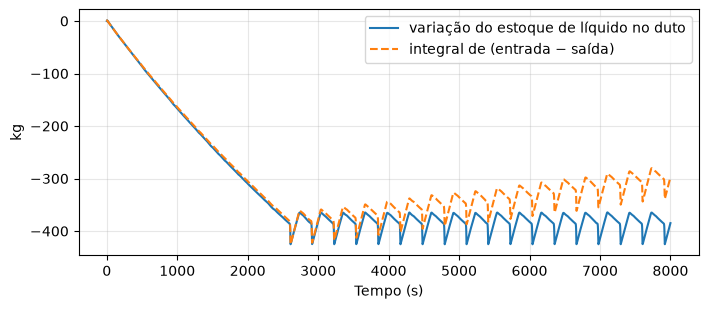

erro final de massa: -87.6 kg (estoque inicial 607.1 kg, entrada acumulada 4241 kg)


In [3]:
h = model.pipes[0].mesh["h"]
mass = np.sum((1 - aG[1:-1]) * fluid.rhoL(P[1:-1] * 1e5) * A * h[:, None], axis=0)
net = np.concatenate([[0.0], np.cumsum(0.5 * ((qLo[0, 1:] - qLo[-1, 1:]) + (qLo[0, :-1] - qLo[-1, :-1])) * np.diff(T))])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(T, mass - mass[0], label="variação do estoque de líquido no duto")
ax.plot(T, net, "--", label="integral de (entrada − saída)")
ax.set_xlabel("Tempo (s)"); ax.set_ylabel("kg"); ax.legend(); ax.grid(alpha=0.3); plt.show()
print(f"erro final de massa: {mass[-1]-mass[0]-net[-1]:.1f} kg (estoque inicial {mass[0]:.1f} kg, entrada acumulada {qL*T[-1]:.0f} kg)")

## Pressões e vazões de saída

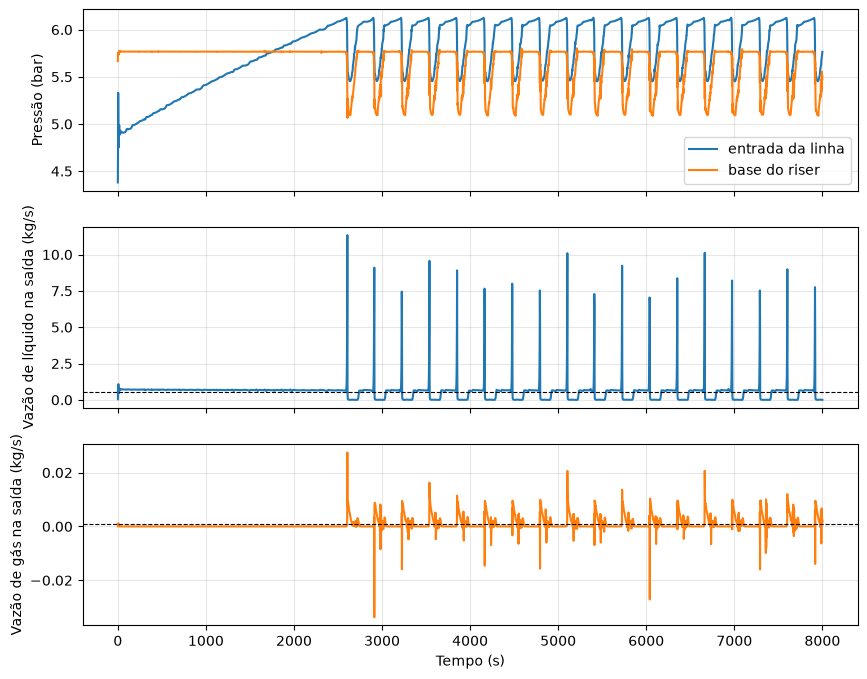

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(T, P[1], label="entrada da linha"); axes[0].plot(T, P[ib], label="base do riser")
axes[0].set_ylabel("Pressão (bar)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(T, qLo[-1]); axes[1].axhline(qL, color="k", ls="--", lw=0.8); axes[1].set_ylabel("Vazão de líquido na saída (kg/s)"); axes[1].grid(alpha=0.3)
axes[2].plot(T, qGo[-1], color="C1"); axes[2].axhline(qG, color="k", ls="--", lw=0.8); axes[2].set_ylabel("Vazão de gás na saída (kg/s)"); axes[2].set_xlabel("Tempo (s)"); axes[2].grid(alpha=0.3)
plt.show()

## Fração de gás ao longo do duto

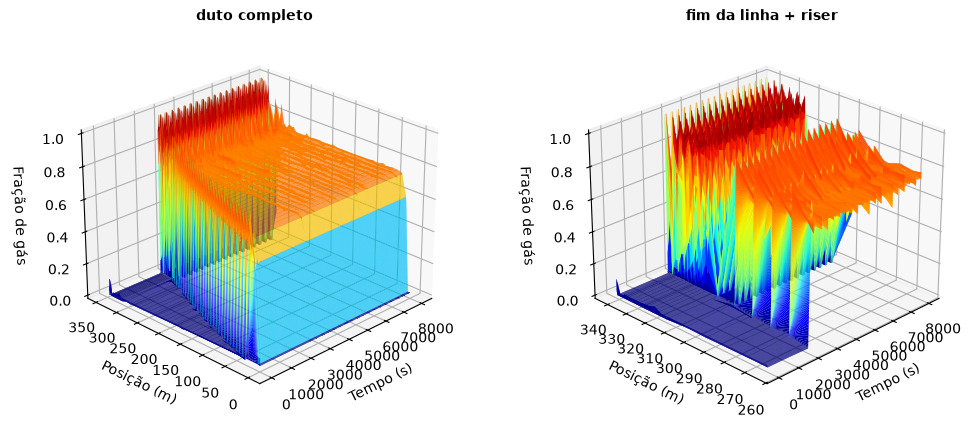

In [5]:
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d"); surface(ax, x, T, aG, zlabel="Fração de gás", title="duto completo")
ax = fig.add_subplot(1, 2, 2, projection="3d"); sl = slice(max(ib - 6, 0), ib + NRISER + 1)
surface(ax, x[sl], T, aG[sl], zlabel="Fração de gás", title="fim da linha + riser")
plt.show()

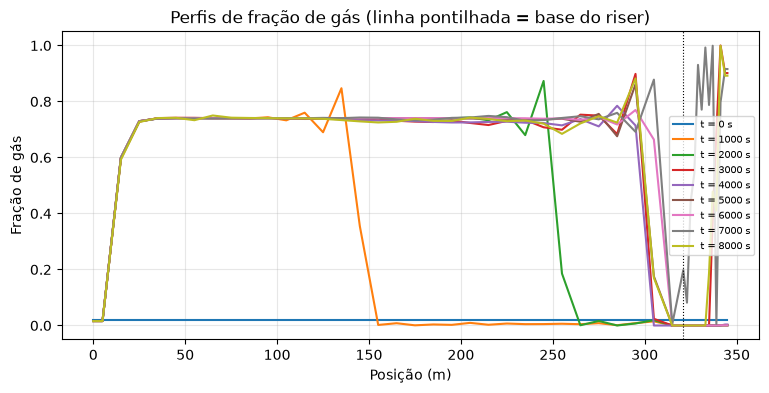

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for t in np.linspace(0, T[-1], 9):
    it = int(np.argmin(np.abs(T - t)))
    ax.plot(x, aG[:, it], label=f"t = {T[it]:.0f} s")
ax.axvline(x[ib], color="k", lw=0.8, ls=":")
ax.set_xlabel("Posição (m)"); ax.set_ylabel("Fração de gás"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.set_title("Perfis de fração de gás (linha pontilhada = base do riser)")
plt.show()

## Ciclos em detalhe e período
Na fase de bloqueio o riser está cheio de líquido e a pressão da linha sobe
lentamente; quando o gás atinge a base do riser, a coluna é expelida (*blowdown*):
a fração de gás no riser passa de 0 a ~0.9 em cerca de 20 s e a vazão de líquido na
saída atinge 10–20 vezes a alimentação; em seguida o riser volta a encher e o ciclo
recomeça.

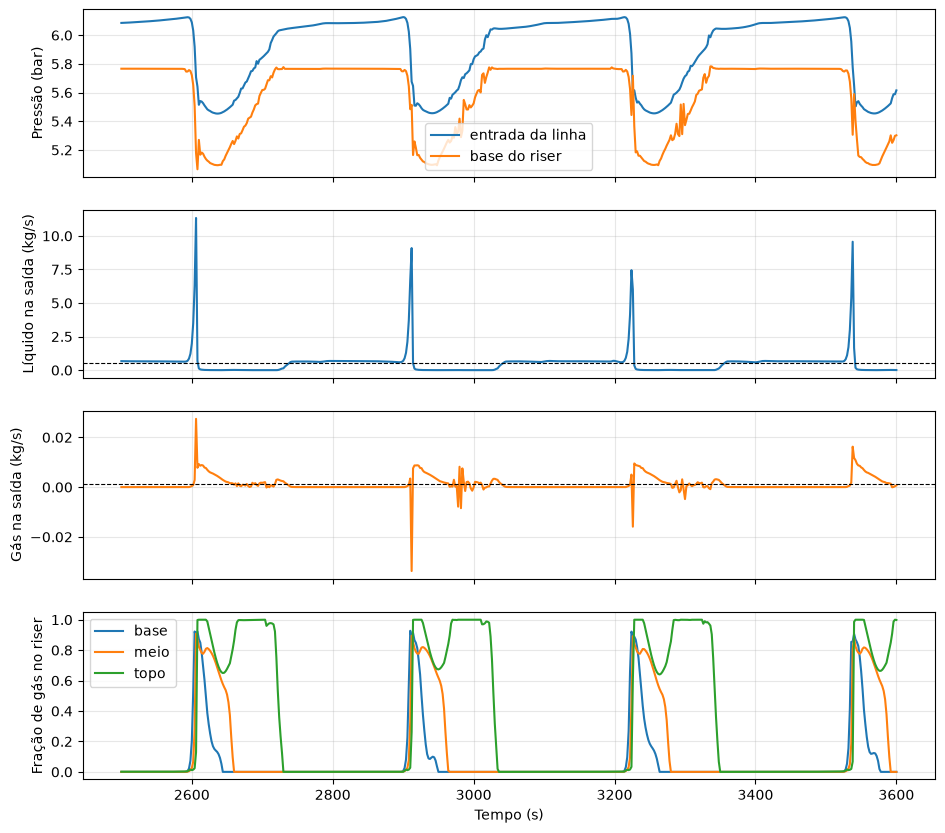

instantes dos picos de líquido (s): [2606, 2912, 3224, 3538, 3852, 4164, 4478, 4792, 5104, 5410, 5726, 6038, 6352, 6664, 6974, 7290, 7602, 7916]
período médio ≈ 312 s; pico máximo 11.3 kg/s (21x a alimentação)


In [7]:
sel = (T >= 2500) & (T <= 3600)      # janela com ~4 ciclos
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
axes[0].plot(T[sel], P[1][sel], label="entrada da linha"); axes[0].plot(T[sel], P[ib][sel], label="base do riser")
axes[0].set_ylabel("Pressão (bar)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(T[sel], qLo[-1][sel]); axes[1].axhline(qL, color="k", ls="--", lw=0.8); axes[1].set_ylabel("Líquido na saída (kg/s)"); axes[1].grid(alpha=0.3)
axes[2].plot(T[sel], qGo[-1][sel], color="C1"); axes[2].axhline(qG, color="k", ls="--", lw=0.8); axes[2].set_ylabel("Gás na saída (kg/s)"); axes[2].grid(alpha=0.3)
axes[3].plot(T[sel], aG[ib + 1][sel], label="base"); axes[3].plot(T[sel], aG[ib + NRISER // 2][sel], label="meio"); axes[3].plot(T[sel], aG[ib + NRISER][sel], label="topo")
axes[3].set_ylabel("Fração de gás no riser"); axes[3].legend(); axes[3].set_xlabel("Tempo (s)"); axes[3].grid(alpha=0.3)
plt.show()
peaks = [i for i in range(1, T.size - 1) if qLo[-1, i] > 2.0 and qLo[-1, i] >= qLo[-1, i - 1] and qLo[-1, i] > qLo[-1, i + 1]]
if len(peaks) > 1:
    tp = T[peaks]; print("instantes dos picos de líquido (s):", np.round(tp).astype(int).tolist())
    print(f"período médio ≈ {np.mean(np.diff(tp)):.0f} s; pico máximo {qLo[-1].max():.1f} kg/s ({qLo[-1].max()/qL:.0f}x a alimentação)")

## Simulação longa (8000 s, malha mais grossa)
Trajetória gravada em `data/severe_slug_run_long.npz` (15 células no trecho
descendente e 5 no riser, tolerância relativa 3e-3, ~50 min de CPU), para
comparação com a malha fina acima. A malha mais grossa encurta o período
(≈ 230 s contra ≈ 312 s) e reduz a altura dos picos, mas preserva o mecanismo:
pressurização lenta, *blowdown* abrupto, pico de produção e reenchimento. O
erro acumulado de massa é mostrado para avaliar a qualidade da solução
(≈ 2.6 % do líquido alimentado em 8000 s; ≈ 2.1 % na malha fina).

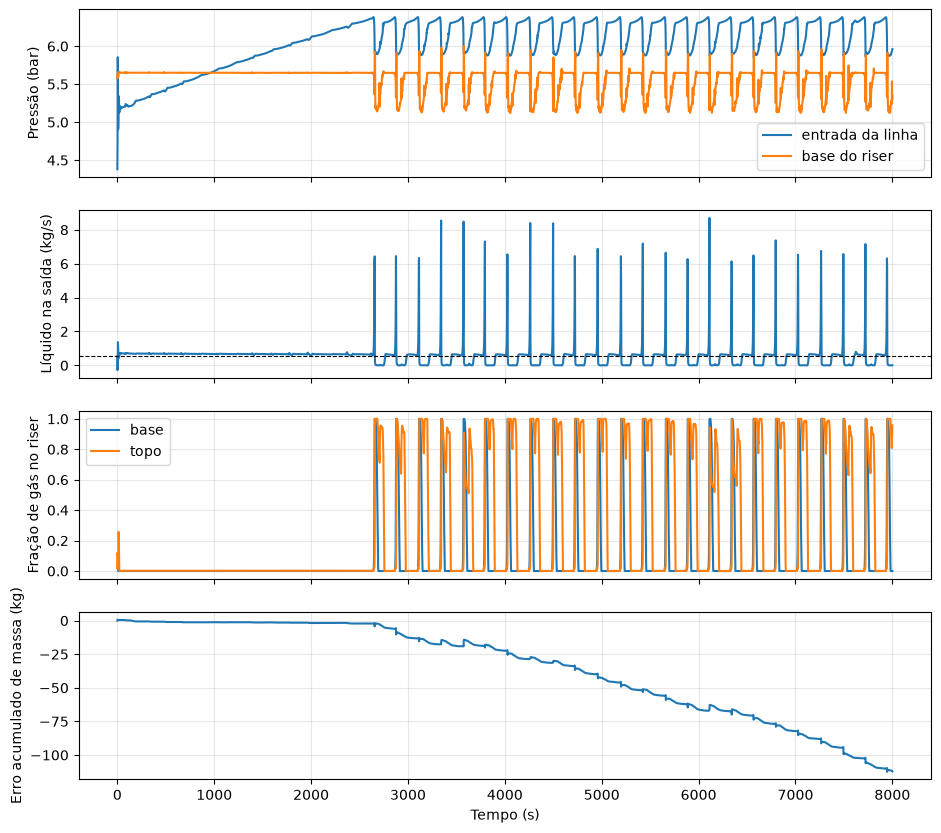

picos (s): [2656, 2876, 3114, 3342, 3574, 3794, 4026, 4262, 4498, 4722, 4958, 5198, 5424, 5660, 5886, 6112, 6340, 6566, 6796, 7026, 7264, 7494, 7722, 7944] | período médio ≈ 230 s | pico máximo 8.7 kg/s
erro final de massa: -112.1 kg em 4241 kg alimentados


In [8]:
DATA_LONG = os.path.join(os.path.dirname(DATA), "severe_slug_run_long.npz")
if os.path.exists(DATA_LONG):
    dl = np.load(DATA_LONG); Tl_, Xl_ = dl["T"], dl["X"]; ml = json.loads(str(dl["meta"]))
    case_l = severe_slug_case(method="fv_upwind", tf=Tl_[-1], dt_out=2.0, qL=qL, qG=qG, D=D, P_out_bar=P_out, L_h1=20.0, L_down=300.0,
                              slope_down_deg=-3.0, H_riser=20.0, L_h2=5.0, n_h1=2, n_down=ml["n_down"], n_riser=ml["n_riser"], n_h2=2,
                              regime=4, single_pipe=True, fluid=fluid, roughness=1e-5,
                              extra={"regime_vertical": 2, "q_switch_L": 0.02 * qL, "q_switch_G": 0.02 * qG,
                                     "switch_frac": ml["switch_frac"], "relax_time": ml["relax_time"]})
    model_l = build_model(case_l); res_l = Results(model_l, Tl_, Xl_); pl = res_l.pipe(0)
    xl = pl["x"]; aGl = pl["out"]["alphaG"]; Pl = pl["out"]["P_bar"]; qLl = pl["out"]["qL"]
    ibl = int(np.argmin(np.abs(xl - (m["L_h1"] + m["L_down"]))))
    hl = model_l.pipes[0].mesh["h"]
    mass_l = np.sum((1 - aGl[1:-1]) * fluid.rhoL(Pl[1:-1] * 1e5) * A * hl[:, None], axis=0)
    net_l = np.concatenate([[0.0], np.cumsum(0.5 * ((qLl[0, 1:] - qLl[-1, 1:]) + (qLl[0, :-1] - qLl[-1, :-1])) * np.diff(Tl_))])
    fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
    axes[0].plot(Tl_, Pl[1], label="entrada da linha"); axes[0].plot(Tl_, Pl[ibl], label="base do riser"); axes[0].set_ylabel("Pressão (bar)"); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(Tl_, qLl[-1]); axes[1].axhline(qL, color="k", ls="--", lw=0.8); axes[1].set_ylabel("Líquido na saída (kg/s)"); axes[1].grid(alpha=0.3)
    axes[2].plot(Tl_, aGl[ibl + 1], label="base"); axes[2].plot(Tl_, aGl[ibl + ml["n_riser"]], label="topo"); axes[2].set_ylabel("Fração de gás no riser"); axes[2].legend(); axes[2].grid(alpha=0.3)
    axes[3].plot(Tl_, mass_l - mass_l[0] - net_l); axes[3].set_ylabel("Erro acumulado de massa (kg)"); axes[3].set_xlabel("Tempo (s)"); axes[3].grid(alpha=0.3)
    plt.show()
    pk = [i for i in range(1, Tl_.size - 1) if qLl[-1, i] > 2.0 and qLl[-1, i] >= qLl[-1, i - 1] and qLl[-1, i] > qLl[-1, i + 1]]
    if len(pk) > 1:
        print("picos (s):", np.round(Tl_[pk]).astype(int).tolist(), f"| período médio ≈ {np.mean(np.diff(Tl_[pk])):.0f} s | pico máximo {qLl[-1].max():.1f} kg/s")
    print(f"erro final de massa: {mass_l[-1]-mass_l[0]-net_l[-1]:.1f} kg em {qL*Tl_[-1]:.0f} kg alimentados")
else:
    print("trajetória longa não encontrada")

## Partida "bloqueada" e dois conjuntos de variáveis de estado

Para não esperar ~2500 s pelo primeiro ciclo, o caso também é iniciado numa
condição construída (`start="blocked"`): bolsão de gás no trecho descendente com a
fração de equilíbrio estratificado (αG ≈ 0.75), riser cheio de líquido,
hidrostática em cada trecho e um salto de pressão na frente do bolsão (margem de
0.3 bar sobre a coluna do riser). O primeiro *blowdown* ocorre em ~12 s e o ciclo
limite é atingido em poucos períodos.

A mesma trajetória (malha grossa, 15 + 5 células, tolerância 3e-3) é calculada
com dois conjuntos de variáveis de estado nas células:

1. **primitivas** (αG, P): as equações de massa são integradas na forma
   quase-linear dαG/dt, dP/dt (como na tese). A conservação de massa é apenas
   aproximada: o erro de truncamento das equações de massa não é cumulativo por
   construção e o limitador de fração de gás nos limites 0/1 descarta massa; o
   erro concentra-se nos *blowdowns* (alguns kg por ciclo).
2. **resíduo conservativo**: o BDF é aplicado às massas por volume
   T(x) = (ρG αG, ρL αL) — resíduo T(x_{n+1}) − Σ a_j T(x_{n−j}) − γ h f(x_{n+1}) = 0,
   resolvido por Newton nas mesmas variáveis primitivas (dT/dx analítica). Os fluxos
   de massa nas faces são multiplicados por um limitador da célula doadora (fluxo
   nulo quando a célula a montante não tem a fase), o que garante positividade sem
   o limitador de fração de gás e mantém o balanço **exato** por célula a cada
   passo. Como T é singular em αG = −γG/γL ≈ −0.01, os limites admitidos para αG são
   [−0.005, 1.005] (um pequeno *undershoot* evita projeções do Newton em 0).

Custo: no modo conservativo a pressão é escrava da massa de líquido através da
compressibilidade (δP/P = γL δmL/mL): o erro de truncamento da massa aparece como
"ruído" de pressão e o controle de passo responde com passos menores (cerca de
2 vezes mais passos nas fases de *blowdown*). Nas variáveis primitivas a pressão é
suave e o mesmo erro de truncamento vira a deriva de massa.

**Como o balanço é verificado.** A integral de (entrada − saída) pela regra dos
trapézios nas saídas gravadas a cada 2 s não é exata (os picos de vazão duram
segundos e os estados gravados são interpolados), por isso o integrador também
acumula os fluxos de contorno com a **mesma recorrência BDF** dos estados
(I_{n+1} = w1 I_n + w2 I_{n−1} + γh g(x_{n+1}), `ImplicitBDF.accum`). Para a
formulação conservativa, estoque(t) − estoque(0) − I(t) é zero a menos de
arredondamento, por construção; para a formulação primitiva a mesma quantidade é
a deriva real de massa da integração.

In [9]:
from mfsim.runs import load_run
from mfsim.analysis import mass_balance


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(meta=r.meta, case=r.case, model=r.model, res=r.res, T=r.T, p=r.pipe(0),
                ib=r.ib,                                   # célula no início do joelho
                balL=r.balance("L"), balG=r.balance("G"),
                acc=r.acc,                                 # integral BDF-consistente dos fluxos de contorno
                p_last=r.p_last,                           # duto que termina no separador (rede: o último)
                aG_riser_base=r.aG_riser_base())


runs = {}
for tag, fname in (("primitivas", "severe_slug_blocked_primitive.npz"), ("conservativo", "severe_slug_blocked_conservative.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs[tag] = load_blocked_run(f); mb = runs[tag]["meta"]
    print(f"{tag:13s}: {mb['n_steps']} passos, {mb['n_rejected']} rejeitados, {mb['cpu']/60:.0f} min de CPU")

primitivas   : 91783 passos, 24105 rejeitados, 18 min de CPU


conservativo : 132679 passos, 39681 rejeitados, 25 min de CPU


### Condição inicial construída

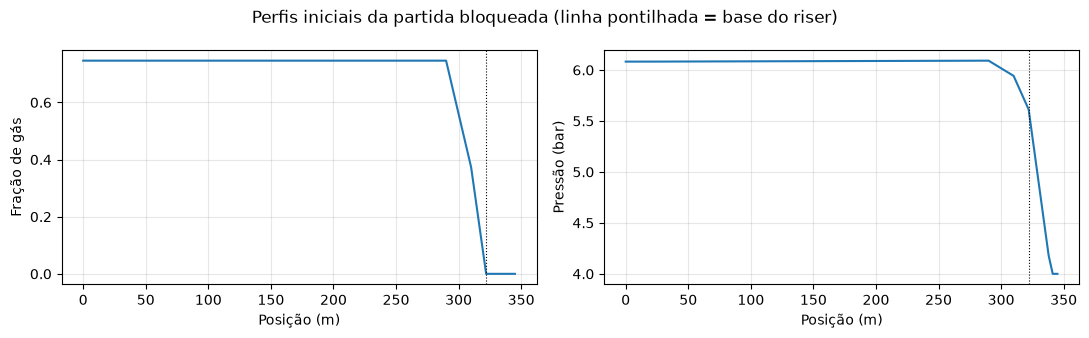

In [10]:
if runs:
    r0 = next(iter(runs.values())); p0 = r0["p"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].plot(p0["x"], p0["out"]["alphaG"][:, 0]); axes[0].set_ylabel("Fração de gás"); axes[0].set_xlabel("Posição (m)")
    axes[1].plot(p0["x"], p0["out"]["P_bar"][:, 0]); axes[1].set_ylabel("Pressão (bar)"); axes[1].set_xlabel("Posição (m)")
    for ax in axes:
        ax.axvline(p0["x"][r0["ib"]], color="k", lw=0.8, ls=":"); ax.grid(alpha=0.3)
    fig.suptitle("Perfis iniciais da partida bloqueada (linha pontilhada = base do riser)"); fig.tight_layout(); plt.show()

### Produção, pressão e balanço de massa nas duas formulações

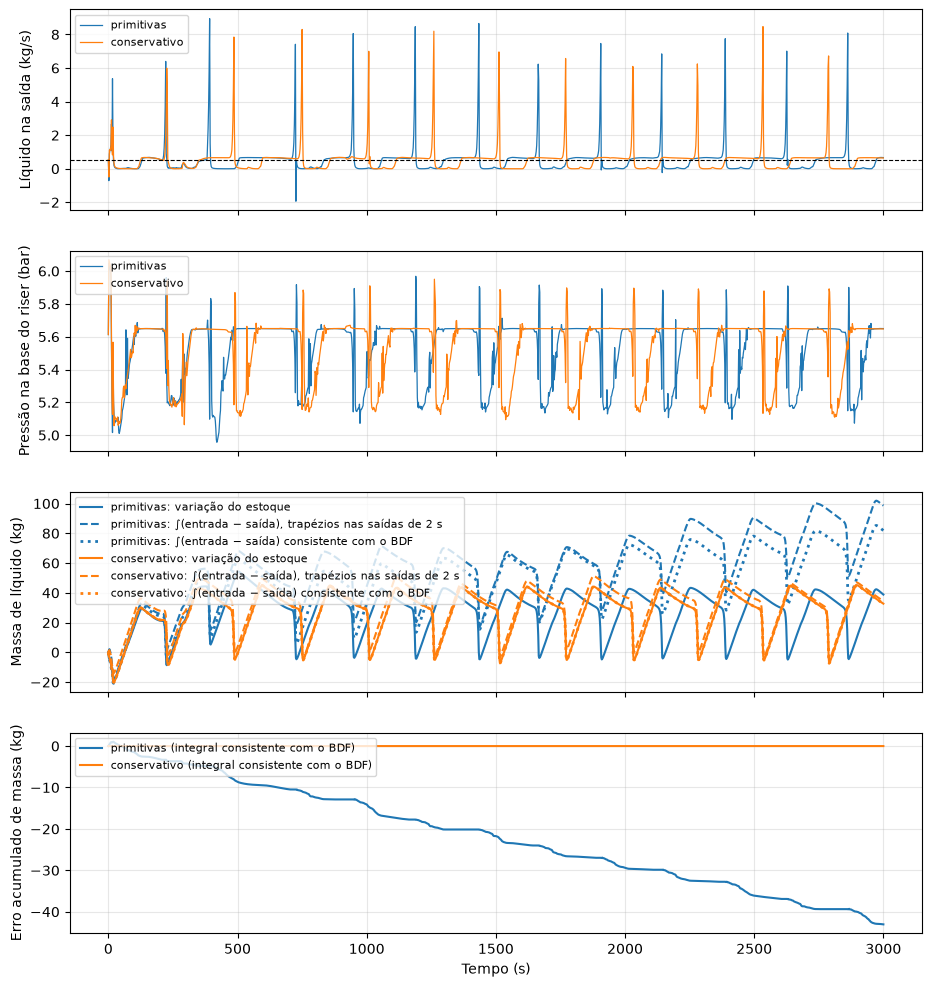

primitivas   : 12 blowdowns, primeiro em 18 s, período médio ≈ 259 s, pico máximo 8.9 kg/s
   erro de massa (trapézios nas saídas de 2 s): líquido -59.74 kg (-3.76 % do alimentado), gás +0.3588 kg (+10.96 %)
   erro de massa (integral consistente com o BDF):   líquido -4.30e+01 kg (-2.71e+00 %), gás +2.78e-01 kg (+8.48e+00 %)
conservativo : 12 blowdowns, primeiro em 20 s, período médio ≈ 254 s, pico máximo 8.5 kg/s
   erro de massa (trapézios nas saídas de 2 s): líquido -1.74 kg (-0.11 % do alimentado), gás +0.2096 kg (+6.40 %)
   erro de massa (integral consistente com o BDF):   líquido -1.14e-05 kg (-7.16e-07 %), gás -7.19e-08 kg (-2.20e-06 %)


In [11]:
if runs:
    fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
    for k, (tag, r) in enumerate(runs.items()):
        T_, p_, ib_ = r["T"], r["p"], r["ib"]
        massL, netL, errL = r["balL"]
        axes[0].plot(T_, p_["out"]["qL"][-1], color=f"C{k}", lw=0.9, label=tag)
        axes[1].plot(T_, p_["out"]["P_bar"][ib_], color=f"C{k}", lw=0.9, label=tag)
        axes[2].plot(T_, massL - massL[0], color=f"C{k}", label=f"{tag}: variação do estoque")
        axes[2].plot(T_, netL, "--", color=f"C{k}", label=f"{tag}: ∫(entrada − saída), trapézios nas saídas de 2 s")
        if r["acc"] is not None:
            axes[2].plot(T_, r["acc"][0], ":", color=f"C{k}", lw=2, label=f"{tag}: ∫(entrada − saída) consistente com o BDF")
            axes[3].plot(T_, massL - massL[0] - r["acc"][0], color=f"C{k}", label=f"{tag} (integral consistente com o BDF)")
        else:
            axes[3].plot(T_, errL, color=f"C{k}", label=f"{tag} (trapézios)")
    axes[0].axhline(qL, color="k", ls="--", lw=0.8); axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na base do riser (bar)")
    axes[2].set_ylabel("Massa de líquido (kg)")
    axes[3].set_ylabel("Erro acumulado de massa (kg)"); axes[3].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper left")
    plt.show()
    for tag, r in runs.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        massL, netL, errL = r["balL"]; massG, netG, errG = r["balG"]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        print(f"{tag:13s}: {nb_} blowdowns, primeiro em {blowdowns(T_, r['p']['out']['P_bar'][1])[0]:.0f} s, período médio ≈ {per:.0f} s, pico máximo {qmax:.1f} kg/s")
        print(f"   erro de massa (trapézios nas saídas de 2 s): líquido {errL[-1]:+.2f} kg ({100*errL[-1]/(qL*T_[-1]):+.2f} % do alimentado), gás {errG[-1]:+.4f} kg ({100*errG[-1]/(qG*T_[-1]):+.2f} %)")
        if r["acc"] is not None:
            eL = massL[-1] - massL[0] - r["acc"][0, -1]; eG = massG[-1] - massG[0] - r["acc"][1, -1]
            print(f"   erro de massa (integral consistente com o BDF):   líquido {eL:+.2e} kg ({100*eL/(qL*T_[-1]):+.2e} %), gás {eG:+.2e} kg ({100*eG/(qG*T_[-1]):+.2e} %)")

### Detalhe de um ciclo nas duas formulações

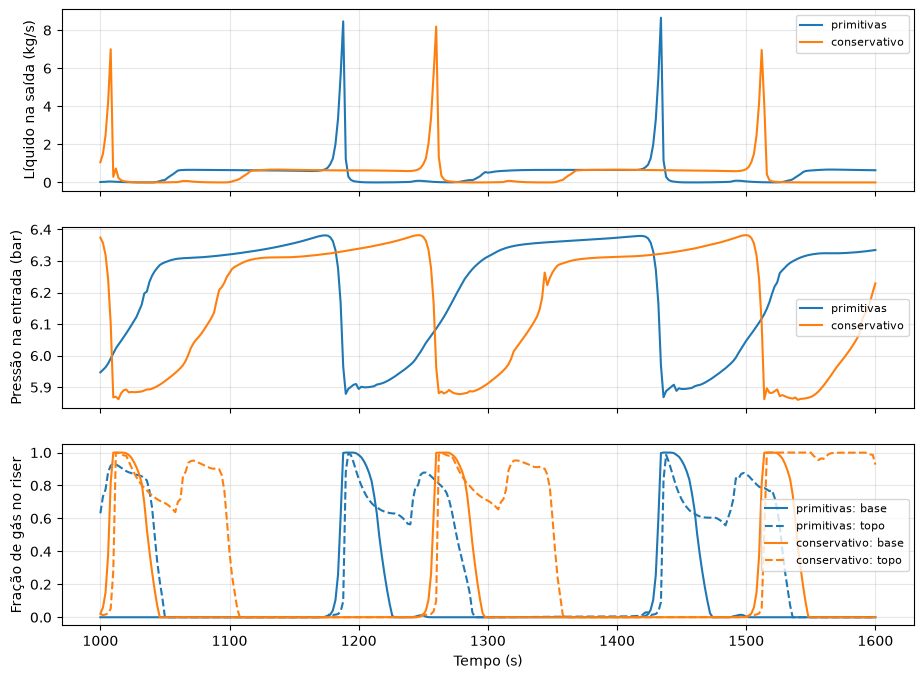

In [12]:
if len(runs) == 2:
    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for k, (tag, r) in enumerate(runs.items()):
        T_, p_, ib_ = r["T"], r["p"], r["ib"]
        sel = (T_ >= 1000) & (T_ <= 1600)
        axes[0].plot(T_[sel], p_["out"]["qL"][-1][sel], color=f"C{k}", label=tag)
        axes[1].plot(T_[sel], p_["out"]["P_bar"][1][sel], color=f"C{k}", label=tag)
        axes[2].plot(T_[sel], p_["out"]["alphaG"][ib_ + 1][sel], color=f"C{k}", label=f"{tag}: base")
        axes[2].plot(T_[sel], p_["out"]["alphaG"][ib_ + r["meta"]["n_riser"]][sel], "--", color=f"C{k}", label=f"{tag}: topo")
    axes[0].set_ylabel("Líquido na saída (kg/s)"); axes[1].set_ylabel("Pressão na entrada (bar)"); axes[2].set_ylabel("Fração de gás no riser"); axes[2].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.show()

## Joelho curvo e transição suave dos fechamentos por ângulo

Na geometria acima a inclinação passa de −3° a 90° entre duas células vizinhas e
o fechamento muda de forma abrupta (estratificado na linha, bolhas no riser,
chave dura em |θ| > 45°). Dois ingredientes removem essa descontinuidade espacial:

1. **joelho em arco** (`elbow_radius`, `n_elbow`): o trecho descendente e o riser
   são ligados por um arco de raio R tangente a ambos, discretizado em elementos
   cujos ângulos crescem gradualmente de −3° a 90° (a inclinação já era um campo
   por elemento; só o traçado muda);
2. **mistura por ângulo** (`vertical_blend`, em graus): o peso do padrão vertical
   é uma rampa C1 (smoothstep) entre 45° − Δ e 45° + Δ, e os fechamentos são
   somados com pesos (1 − w) e w. Sem o arco a mistura só atua na face do joelho
   (θ ≈ 43.5°) e **piora** a convergência (face com metade de cada fechamento entre
   duas células "puras"); com o arco ela reduz os passos em ~13 % na fase inicial.

Abaixo, o mesmo caso (partida bloqueada, malha grossa, 3000 s) com R = 5 m, 4
elementos no arco e Δ = 20°, nas duas formulações, comparado com o joelho
anguloso. Os ciclos são contados pelos *blowdowns* (mínimos da pressão na
entrada), porque um blowdown pode ter mais de um pico de vazão.

In [13]:
runs_arc = {}
for tag, fname in (("primitivas", "severe_slug_blocked_primitive_arc.npz"), ("conservativo", "severe_slug_blocked_conservative_arc.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs_arc[tag] = load_blocked_run(f)
    mb = runs_arc[tag]["meta"]
    print(f"{tag:13s} (arco R = {mb['elbow_radius']} m, {mb['n_elbow']} elementos, Δ = {mb['vertical_blend']}°): "
          f"{mb['n_steps']} passos, {mb['n_rejected']} rejeitados, {mb['cpu']/60:.0f} min de CPU")

primitivas    (arco R = 5.0 m, 4 elementos, Δ = 20.0°): 128021 passos, 31494 rejeitados, 24 min de CPU


conservativo  (arco R = 5.0 m, 4 elementos, Δ = 20.0°): 112474 passos, 29359 rejeitados, 22 min de CPU


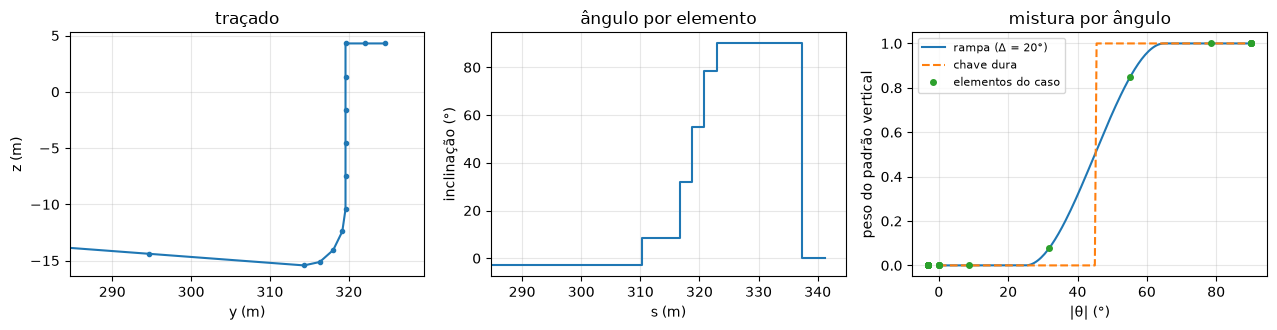

In [14]:
if runs_arc:
    r = next(iter(runs_arc.values())); case_a = r["case"]; model_a = r["model"]
    from mfsim.geometry import pipe_mesh
    mesh_a = pipe_mesh(case_a.pipes[0].x, case_a.pipes[0].y, case_a.pipes[0].z, case_a.pipes[0].n_elements)
    th_deg = np.rad2deg(mesh_a["theta"]); s_mid = 0.5 * (mesh_a["s"][1:] + mesh_a["s"][:-1])
    w = model_a.pipes[0].model.vertical_weight(mesh_a["theta"])
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    axes[0].plot(mesh_a["xyz"][:, 1], mesh_a["xyz"][:, 2], ".-"); axes[0].set_xlabel("y (m)"); axes[0].set_ylabel("z (m)"); axes[0].set_title("traçado")
    axes[0].set_xlim(mesh_a["xyz"][-1, 1] - 40, mesh_a["xyz"][-1, 1] + 5)
    axes[1].step(s_mid, th_deg, where="mid"); axes[1].set_xlabel("s (m)"); axes[1].set_ylabel("inclinação (°)"); axes[1].set_title("ângulo por elemento")
    axes[1].set_xlim(case_a.meta["s_elbow0"] - 30, case_a.meta["s_elbow0"] + 30)
    ang = np.linspace(0, 90, 181)
    axes[2].plot(ang, model_a.pipes[0].model.vertical_weight(np.deg2rad(ang)), label="rampa (Δ = 20°)")
    axes[2].plot(ang, (ang > 45).astype(float), "--", label="chave dura"); axes[2].plot(th_deg, w, "o", ms=4, label="elementos do caso")
    axes[2].set_xlabel("|θ| (°)"); axes[2].set_ylabel("peso do padrão vertical"); axes[2].legend(fontsize=8); axes[2].set_title("mistura por ângulo")
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout(); plt.show()

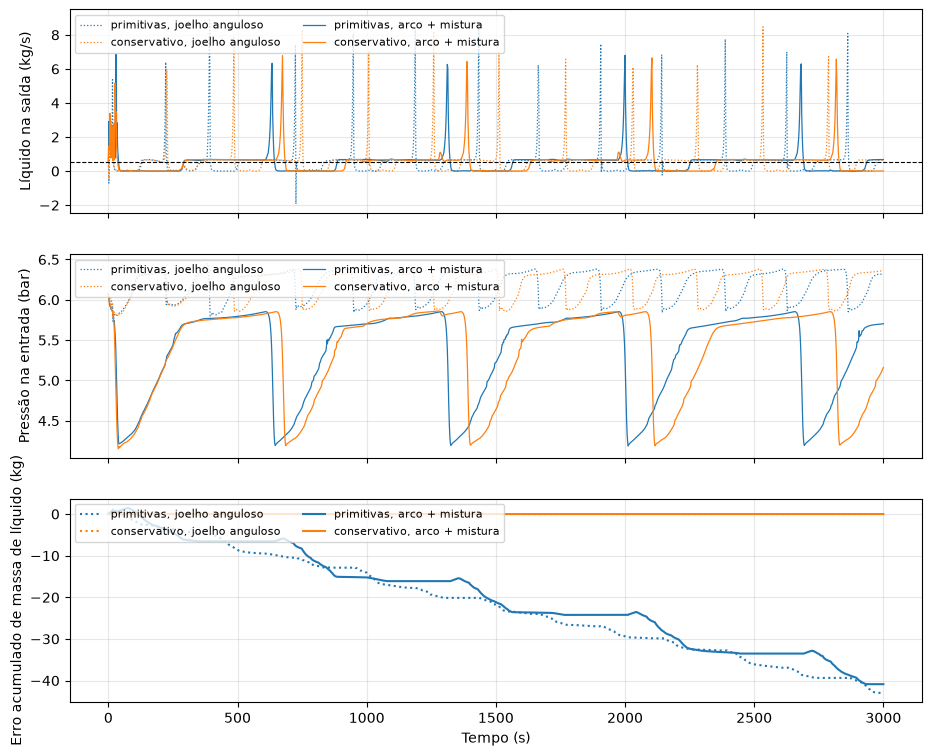

primitivas    joelho anguloso:   91783 passos | 12 blowdowns, período ≈ 259 s, pico máximo 8.9 kg/s, P_in 5.73–6.45 bar | erro de massa de líquido -4.30e+01 kg
conservativo  joelho anguloso:  132679 passos | 12 blowdowns, período ≈ 254 s, pico máximo 8.5 kg/s, P_in 5.78–6.39 bar | erro de massa de líquido -1.14e-05 kg
primitivas    arco + mistura :  128021 passos | 5 blowdowns, período ≈ 662 s, pico máximo 6.8 kg/s, P_in 4.19–6.06 bar | erro de massa de líquido -4.09e+01 kg
conservativo  arco + mistura :  112474 passos | 5 blowdowns, período ≈ 698 s, pico máximo 6.8 kg/s, P_in 4.15–6.06 bar | erro de massa de líquido -1.01e-05 kg


In [15]:
if runs_arc:
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    for k, (tag, r) in enumerate(list(runs.items()) + list(runs_arc.items())):
        arc = r["meta"].get("n_elbow", 0) > 0
        lab = f"{tag}, {'arco + mistura' if arc else 'joelho anguloso'}"
        ls = "-" if arc else ":"
        T_, p_, ib_ = r["T"], r["p"], r["ib"]
        axes[0].plot(T_, p_["out"]["qL"][-1], ls, color=f"C{k % 2}", lw=0.9, label=lab)
        axes[1].plot(T_, p_["out"]["P_bar"][1], ls, color=f"C{k % 2}", lw=0.9, label=lab)
        massL, netL, _ = r["balL"]
        if r["acc"] is not None:
            axes[2].plot(T_, massL - massL[0] - r["acc"][0], ls, color=f"C{k % 2}", label=lab)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8); axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)"); axes[2].set_ylabel("Erro acumulado de massa de líquido (kg)"); axes[2].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper left", ncol=2)
    plt.show()
    for tag, r in list(runs.items()) + list(runs_arc.items()):
        arc = r["meta"].get("n_elbow", 0) > 0
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        massL, _, _ = r["balL"]; eL = (massL[-1] - massL[0] - r["acc"][0, -1]) if r["acc"] is not None else np.nan
        print(f"{tag:13s} {'arco + mistura ' if arc else 'joelho anguloso'}: {r['meta']['n_steps']:7d} passos | {nb_} blowdowns, período ≈ {per:.0f} s, "
              f"pico máximo {qmax:.1f} kg/s, P_in {r['p']['out']['P_bar'][1].min():.2f}–{r['p']['out']['P_bar'][1].max():.2f} bar | erro de massa de líquido {eL:+.2e} kg")

### Fração de gás junto ao joelho
Perfis em instantes de um ciclo (formulação conservativa): com o arco a frente
de líquido e a entrada de gás no riser são resolvidas em células de ângulo
intermediário em vez de saltarem entre a última célula da linha e a primeira do riser.

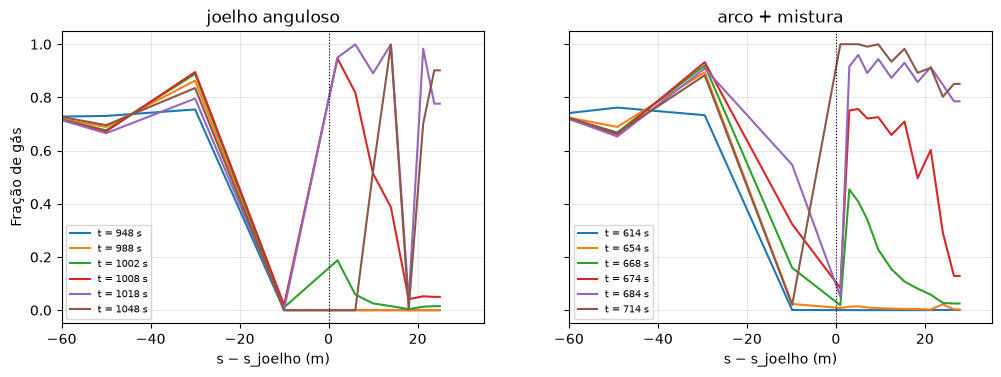

In [16]:
if "conservativo" in runs_arc and "conservativo" in runs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for ax, (lab, r) in zip(axes, (("joelho anguloso", runs["conservativo"]), ("arco + mistura", runs_arc["conservativo"]))):
        T_, p_ = r["T"], r["p"]; x_ = p_["x"]; s0 = r["case"].meta["s_elbow0"]
        q_ = p_["out"]["qL"][-1]
        pk = [i for i in range(1, T_.size - 1) if q_[i] > 2.0 and q_[i] >= q_[i - 1] and q_[i] > q_[i + 1]]
        i0 = pk[5] if len(pk) > 6 else T_.size // 2
        for dt_ in (-60, -20, -5, 0, 10, 40):
            it = min(max(i0 + dt_ // 2, 0), T_.size - 1)
            ax.plot(x_ - s0, p_["out"]["alphaG"][:, it], label=f"t = {T_[it]:.0f} s")
        ax.axvline(0, color="k", lw=0.8, ls=":"); ax.set_xlim(-60, 35); ax.set_xlabel("s − s_joelho (m)"); ax.set_title(lab); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    axes[0].set_ylabel("Fração de gás"); plt.show()

## Malha não uniforme (refinamento no joelho)

Os maiores gradientes estão no "pescoço": fim do trecho descendente, arco e base
do riser (frente de líquido, entrada do gás no riser). `pipe_mesh` aceita, por
trecho, a razão entre o último e o primeiro elemento (`grading`, progressão
geométrica): no trecho descendente `grading_down` < 1 refina para o joelho e no
riser `grading_riser` > 1 refina a base. O esquema de volumes finitos usa as
distâncias entre centros de células (`dx_faces`), por isso não precisa de
alteração. Quatro malhas, todas com arco (R = 5 m, 4 elementos) e mistura por
ângulo (Δ = 20°), formulação conservativa, partida bloqueada, 3000 s:

| malha | células | descendente (m) | riser (m) |
|---|---|---|---|
| uniforme 15/5 | 28 | 19.6 | 2.95 |
| graduada 15/5 (0.25 / 3) | 28 | 35.9 → 9.0 | 1.58 → 4.74 |
| uniforme 30/10 | 48 | 9.8 | 1.47 |
| graduada 30/10 (0.25 / 3) | 48 | 18.1 → 4.5 | 0.80 → 2.40 |

A pergunta é se, a custo igual (mesmo número de células), a malha graduada se
aproxima mais da malha fina — e se a fina graduada muda o resultado da fina
uniforme (indicador de convergência de malha).

**Modo acústico do tampão de líquido.** A primeira tentativa com a malha fina
graduada (0.8 m na base do riser) rastejou com passos de 1 ms. O diagnóstico com
saída a cada 5 ms mostrou um modo acústico do tampão de líquido que se forma na
base do riser depois de cada *blowdown* (≈ 8 m de líquido entre o bolsão da linha
e o gás do riser): vazão de líquido e pressão oscilando a ≈ 16–20 Hz = c/2L, com
c = 258 m/s (expoente politrópico 100). O gradiente de pressão centrado não
amortece acústica, o BDF2 quase não dissipa e o controlador de passo resolve a
oscilação. Remédio numérico adotado: viscosidade artificial linear ν = 0.01·c·h
nas equações de momento (`art_visc`; some com h → 0, taxa ν·k² desprezível para
ondas longas), que reduz o custo em todas as malhas; a regularização hiperbólica
da seção seguinte (`low_void_regime` + `interfacial_pressure`) é mostrada como
quinta trajetória na malha grossa. As trajetórias desta seção têm `art_visc`; o
custo sem ele (malha grossa 112 mil passos, graduada 166 mil, fina 262 mil) está
no README.

In [17]:
runs_mesh = {}
for tag, fname in (("uniforme 15/5", "severe_slug_blocked_conservative_arc_av.npz"), ("graduada 15/5", "severe_slug_blocked_conservative_arc_graded_av.npz"),
                   ("uniforme 30/10", "severe_slug_blocked_conservative_arc_fine_av.npz"), ("graduada 30/10", "severe_slug_blocked_conservative_arc_fine_graded_av.npz"),
                   ("uniforme 15/5 + regularização", "severe_slug_blocked_conservative_arc_av_reg.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs_mesh[tag] = load_blocked_run(f)

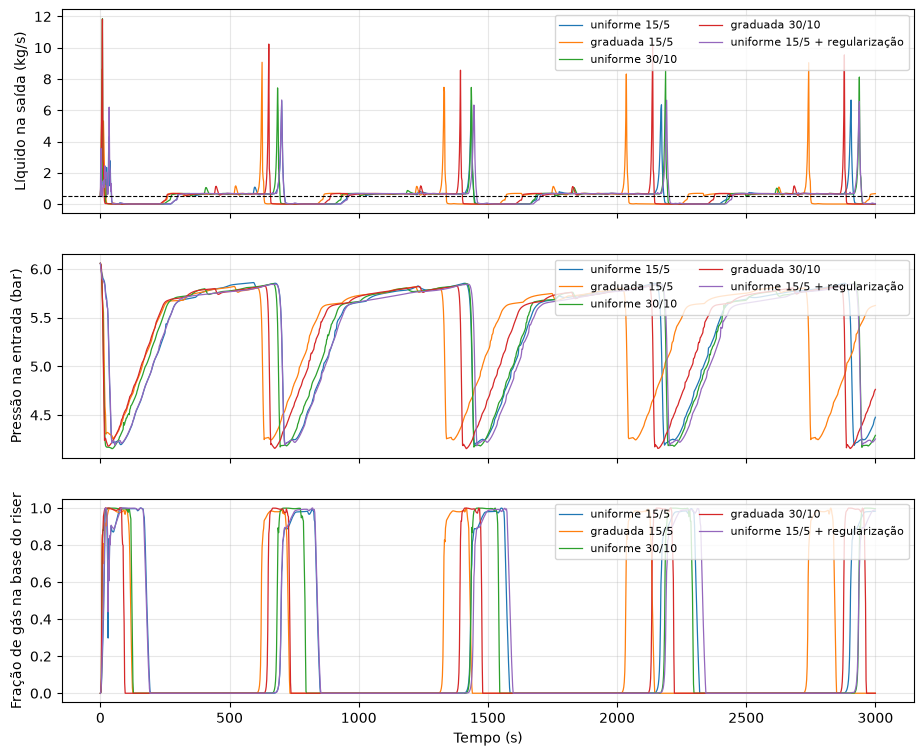

malha              passos     CPU blowdowns  período  pico máx   P_in (bar)  erro massa L
uniforme 15/5       85653    20 min         5    710 s    6.7 kg/s  4.19–5.86     -5.1e-06 kg
graduada 15/5      145286    35 min         5    682 s    9.1 kg/s  4.24–5.82     -2.0e-04 kg
uniforme 30/10     201553    58 min         5    726 s    8.6 kg/s  4.17–5.85     -9.5e-06 kg
graduada 30/10     302648    83 min         5    718 s   10.2 kg/s  4.15–5.83     -1.3e-05 kg
uniforme 15/5 + regularização    85418    22 min         5    724 s    6.7 kg/s  4.19–5.84     -5.3e-06 kg


In [18]:
if runs_mesh:
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    for k, (tag, r) in enumerate(runs_mesh.items()):
        T_, p_ = r["T"], r["p"]
        axes[0].plot(T_, p_["out"]["qL"][-1], lw=0.9, label=tag)
        axes[1].plot(T_, p_["out"]["P_bar"][1], lw=0.9, label=tag)
        axes[2].plot(T_, p_["out"]["alphaG"][r["ib"] + r["meta"]["n_elbow"] + 1], lw=0.9, label=tag)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8); axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)"); axes[2].set_ylabel("Fração de gás na base do riser"); axes[2].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper right", ncol=2)
    plt.show()
    print(f"{'malha':16s} {'passos':>8s} {'CPU':>7s} {'blowdowns':>9s} {'período':>8s} {'pico máx':>9s} {'P_in (bar)':>12s} {'erro massa L':>13s}")
    for tag, r in runs_mesh.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        massL, _, _ = r["balL"]; eL = (massL[-1] - massL[0] - r["acc"][0, -1]) if r["acc"] is not None else np.nan
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(f"{tag:16s} {r['meta']['n_steps']:8d} {r['meta']['cpu']/60:5.0f} min {nb_:9d} {per:6.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f} {eL:+12.1e} kg")

### Perfis junto ao joelho num instante do blowdown
Mesmo instante relativo ao pico de líquido (≈ 6 s antes do pico), em cada malha.

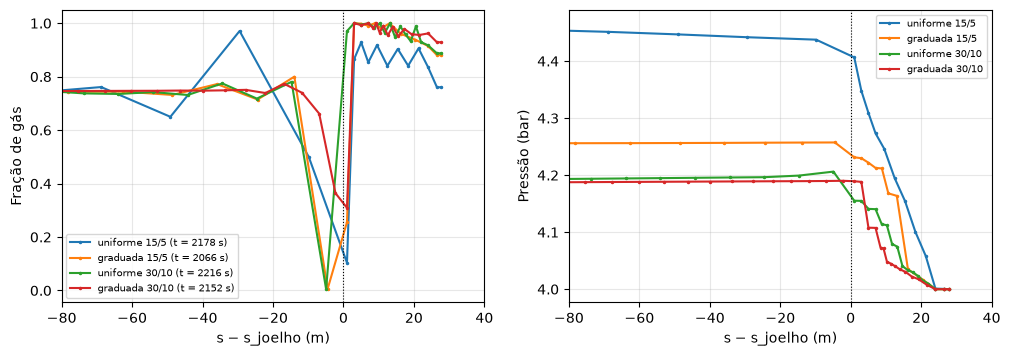

In [19]:
if runs_mesh:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for k, (tag, r) in enumerate(runs_mesh.items()):
        if "regulariza" in tag:
            continue
        T_, p_ = r["T"], r["p"]; x_ = p_["x"]; s0 = r["case"].meta["s_elbow0"]
        tb = blowdowns(T_, p_["out"]["P_bar"][1]); tb = tb[tb > 600]
        if tb.size == 0:
            continue
        it = max(int(np.argmin(np.abs(T_ - tb[len(tb) // 2]))) - 3, 0)
        axes[0].plot(x_ - s0, p_["out"]["alphaG"][:, it], ".-", ms=3, label=f"{tag} (t = {T_[it]:.0f} s)")
        axes[1].plot(x_ - s0, p_["out"]["P_bar"][:, it], ".-", ms=3, label=tag)
    for ax, yl in zip(axes, ("Fração de gás", "Pressão (bar)")):
        ax.axvline(0, color="k", lw=0.8, ls=":"); ax.set_xlim(-80, 40); ax.set_xlabel("s − s_joelho (m)"); ax.set_ylabel(yl); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    plt.show()

## Hiperbolicidade dos fechamentos e regularização

O modelo a dois fluidos a 4 equações só é hiperbólico graças às correções de
pressão dos fechamentos (hidrostática do estratificado, 0.25·ρL·slip² das
bolhas). Onde essas correções falham, as velocidades características ficam
complexas, o problema de valor inicial é mal posto e a solução numérica
desenvolve oscilações na escala da malha, que pioram com o refinamento (foi o que
aconteceu na malha fina graduada: *chattering* da vazão de líquido no joelho com
período < 0.1 s e passos de 1 ms).

O mapa abaixo mostra max|Im λ| (m/s) em função da fração de gás e do
escorregamento para os fechamentos usados no caso:

* **estratificado** (linha): mal posto para αG ≲ 0.003 **mesmo sem
  escorregamento** — é o limite de camada de gás muito fina (hL → D), e é
  exatamente onde toda célula cheia de líquido é avaliada (αG cortado em 1e−3);
* **bolhas** (riser): mal posto em baixa fração com escorregamento (caso clássico);
* **tensão superficial** não resolve: é um termo dispersivo de 3ª ordem que não
  altera as características de 1ª ordem; limita o crescimento de ondas curtas, mas
  com σ = 0.05 N/m o corte capilar é milimétrico, irrelevante para células de metros;
* o que funciona: **padrão de bolhas abaixo de αG = 1 %** (`low_void_regime`,
  rampa C1; uma camada estratificada com 1 % da área não é física) **mais o termo de
  pressão interfacial** de Bestion/CATHARE, δ·αG·αL·ρG·ρL/(αG·ρL + αL·ρG)·(vG − vL)²
  com δ ≥ 1 (`interfacial_pressure`), que torna o modelo disperso hiperbólico para
  qualquer escorregamento. A combinação deixa o mapa inteiro com características reais.

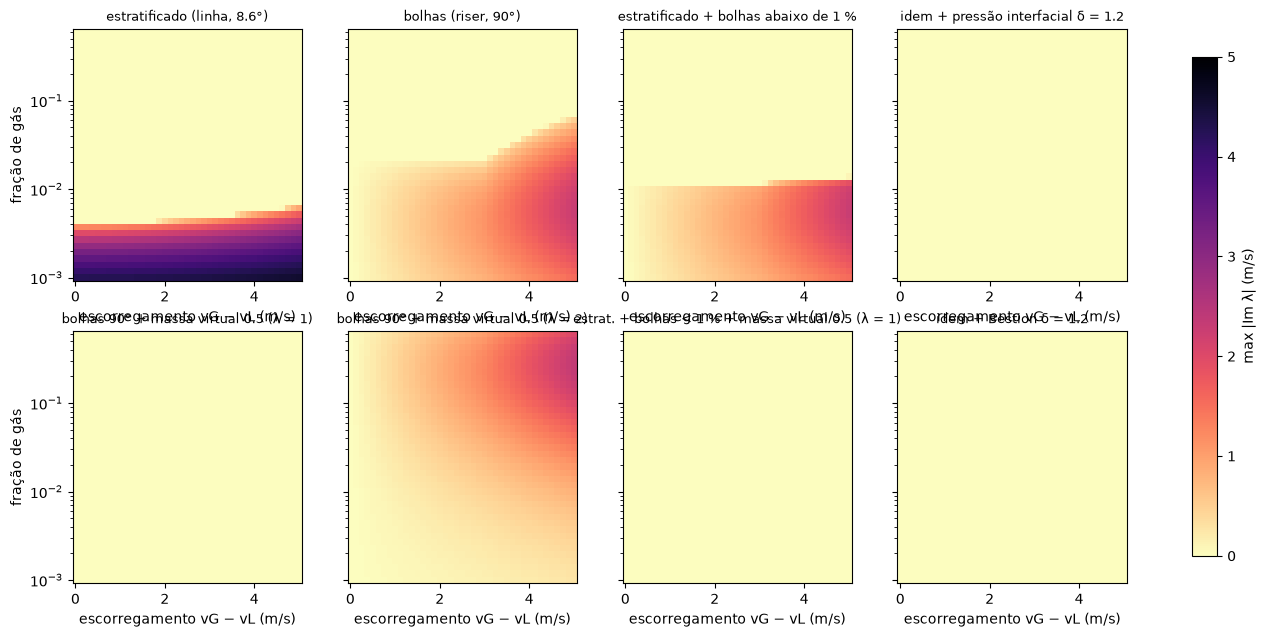

In [20]:
from mfsim.models.base import PipeParams
from mfsim.models.twofluid import TwoFluidModel
rhoL_, rhoG_, _, _ = fluid.props(6e5)
aG_grid = np.logspace(-3, np.log10(0.6), 40); slip_grid = np.linspace(0.0, 5.0, 41)
variants = {"estratificado (linha, 8.6°)": dict(regime=4, theta=8.6),
            "bolhas (riser, 90°)": dict(regime=4, regime_vertical=2, theta=90.0),
            "estratificado + bolhas abaixo de 1 %": dict(regime=4, low_void_regime=2, theta=8.6),
            "idem + pressão interfacial δ = 1.2": dict(regime=4, low_void_regime=2, interfacial_pressure=1.2, theta=8.6),
            "bolhas 90° + massa virtual 0.5 (λ = 1)": dict(regime=4, regime_vertical=2, theta=90.0, virtual_mass=0.5),
            "bolhas 90° + massa virtual 0.5 (λ = 2)": dict(regime=4, regime_vertical=2, theta=90.0, virtual_mass=0.5, vm_lambda=2.0),
            "estrat. + bolhas < 1 % + massa virtual 0.5 (λ = 1)": dict(regime=4, low_void_regime=2, theta=8.6, virtual_mass=0.5),
            "idem + Bestion δ = 1.2": dict(regime=4, low_void_regime=2, theta=8.6, virtual_mass=0.5, interfacial_pressure=1.2)}
fig, axes = plt.subplots(2, 4, figsize=(17, 7.2), sharey=True)
axes = axes.ravel()
for ax, (name, v) in zip(axes, variants.items()):
    v = dict(v); theta = v.pop("theta")
    m_ = TwoFluidModel(fluid, PipeParams(D=D, eps=1e-5, PR=1e6, vertical_angle=45.0, vertical_blend=20.0, low_void_alpha=0.01, **v))
    Z = np.zeros((aG_grid.size, slip_grid.size))
    for i, aG_ in enumerate(aG_grid):
        vL_ = 0.5 / (rhoL_ * (1 - aG_) * A)
        y = np.array([[aG_, 0.6, 0.5, rhoG_ * aG_ * A * (vL_ + s_)] for s_ in slip_grid])
        Z[i] = np.abs(m_.eigenvalues(y, np.deg2rad(np.full(slip_grid.size, theta))).imag).max(axis=1)
    pc = ax.pcolormesh(slip_grid, aG_grid, Z, shading="nearest", vmin=0, vmax=5, cmap="magma_r")
    ax.set_yscale("log"); ax.set_xlabel("escorregamento vG − vL (m/s)"); ax.set_title(name, fontsize=9)
axes[0].set_ylabel("fração de gás"); axes[4].set_ylabel("fração de gás"); fig.colorbar(pc, ax=axes, label="max |Im λ| (m/s)", shrink=0.9)
plt.show()

**Massa virtual** (termo de Drew & Lahey, `virtual_mass` = C_vm pesado pelo indicador
de bolhas, `vm_lambda` = forma objetiva): a forma simples (λ = 2, só a diferença de
acelerações) piora a má-posição; a forma objetiva (λ = 1) com C_vm = 0.5 torna o
modelo hiperbólico em todo o mapa, tal como Bestion, mas com um termo físico. No
ciclo as duas regularizações se comportam de modo diferente (tabela abaixo): Bestion
não muda o ciclo e custa 1.6× mais passos; a massa virtual muda o intervalo entre
blowdowns em +7–10 % ao mesmo custo, e o faz igualmente nas formas λ = 1 e λ = 2, ou
seja, pelo acoplamento das inércias no riser em bolhas, não pela regularização. A
sensibilidade ao atrito interfacial do estratificado (`fi_mult` ×0.5/×2, Taitel–Dukler
contra Andritsos–Hanratty) é pequena: ±2 % no intervalo, ±8 % nos picos. Consequência
prática: a malha fina graduada no pescoço (30/10, razões 0.25/3), inviável com o alvo
de fração real (302.6k passos, 83 min, *chattering* nas células cheias de líquido),
custa 77.9k passos / 4 min com `noslip` e 68.9k / 3 min com massa virtual + bolhas
abaixo de 1 %; o alongamento do intervalo pela massa virtual mantém-se com o
refinamento (778 s contra 710 s).

**Contracorrente no riser.** Com bolhas prescritas no riser, o filme de líquido que
fica depois do blowdown (riser com mais de 90 % de gás em ~20 % do tempo) nunca
drena: o fechamento de bolhas a 95–100 % de gás exerce um arrasto de 3 a 4 ordens
de grandeza acima da gravidade e o líquido residual é expulso pelo topo (sobe a
mais de 0.5 m/s em 28 % do tempo, desce em 5 %). O fechamento anular dá um balanço
de forças sensato no filme, com inundação implícita perto de vG ≈ 10 m/s (Wallis
para D = 5 cm: ~8 m/s). A regra `high_void_regime=1` (anular acima de 90 % de gás,
rampa C1) deixa o filme drenar em 56–66 % desse tempo e alonga o intervalo entre
blowdowns em ~10 %; combinada com massa virtual e bolhas abaixo de 1 % é a corrida
mais barata (16.8k passos, 39 s) e passa a ser a configuração recomendada.

**Fechamento do riser: intermitente contra bolhas.** Nos estados do blowdown o
fechamento de bolhas exerce sobre o líquido um arrasto de −19 a −2400 N/m, o
intermitente (unidade de slug da tese) de −0.03 a −128 N/m: as bolhas carregam o
líquido pelo gás com muito mais eficiência (picos de 7–8 kg/s contra 4–6 com o IPE).
Mais importante: com `regime_vertical=3` **não há ciclo**; depois do primeiro
blowdown o sistema vai para golfadas contínuas pelo riser (αG 0.01–0.3, P_in ≈ 5.8
bar, produção 0.3–1.2 kg/s), com ou sem as regras físicas. Isto é coerente com o
critério de Bøe para o caso (vSL mínimo 1.03 m/s contra 0.30 de alimentação): o
ciclo obtido com bolhas prescritas é sustentado pelo fechamento, que retém o gás na
base do riser. A varredura em vSL acima do limiar de Bøe, com os dois fechamentos,
está na célula seguinte.

**Volume de gás a montante** (`upstream_volume`: vértice dinâmico de volume V com as
vazões de alimentação): o ciclo mantém-se com 0.1 a 2 m³ e o pico de líquido cresce
(6.1 → 9.3 kg/s), mas o vértice é um tanque de mistura cuja fração de gás cai a ≈ 0.05
(o líquido alimentado acumula), logo o volume de gás efetivo é ~5 % do nominal e a taxa
de pressurização da linha não muda. O gasoduto a montante representa-se prolongando a
linha horizontal de entrada (`L_h1` = 200 e 500 m, com o estratificado a guardar o gás
no topo): ver a tabela da fronteira. O vértice tipo separador fica pendente.

**Lei do gás** (γG politrópico): 1.3 (adiabático) encurta o intervalo entre blowdowns em
18 % no caso base e 9 % na linha longa e baixa os picos 10 %; 1.0 (isotérmico) alonga 4 %.
Gás mais rígido pressuriza o bolsão mais depressa; a amplitude de pressão não muda.

As duas tabelas abaixo são o diagnóstico do filme: o balanço de forças no filme (αG = 0.95, riser
vertical) segundo cada fechamento, e a fração do tempo em que o filme drena nas
corridas gravadas.

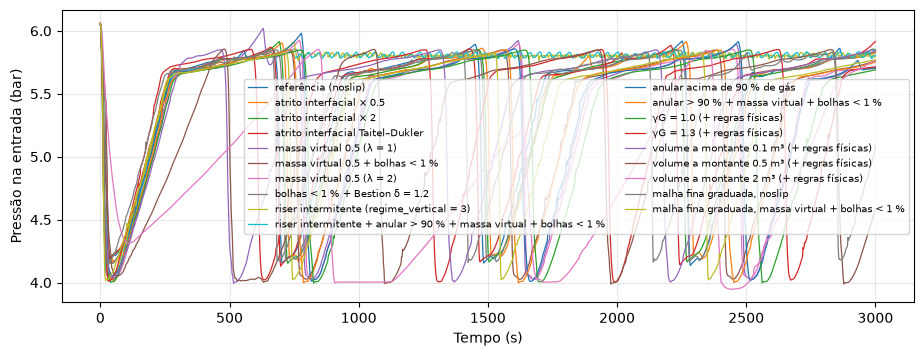

configuração                           passos    CPU blowdowns intervalo  pico máx   P_in (bar)
referência (noslip)                     25228    47 s         4     749 s    7.1 kg/s  4.14–5.92
atrito interfacial × 0.5                30578    78 s         4     759 s    7.5 kg/s  4.17–5.91
atrito interfacial × 2                  20217    53 s         4     746 s    6.6 kg/s  4.15–5.92
atrito interfacial Taitel–Dukler        27250    71 s         4     735 s    6.5 kg/s  4.13–5.92
massa virtual 0.5 (λ = 1)               23597    50 s         4     826 s    7.6 kg/s  4.02–6.02
massa virtual 0.5 + bolhas < 1 %        21919    46 s         4     801 s    6.3 kg/s  4.03–5.85
massa virtual 0.5 (λ = 2)               20003    47 s         4     823 s    7.8 kg/s  4.02–5.93
bolhas < 1 % + Bestion δ = 1.2          41437    86 s         4     748 s    5.9 kg/s  4.16–5.85
riser intermitente (regime_vertical = 3)   101181   293 s         1     nan s    2.0 kg/s  4.36–5.91
riser intermitente + anular

In [21]:
runs_phys = {}
for tag, fname in (("referência (noslip)", "severe_slug_blocked_conservative_arc_tol_noslip.npz"),
                   ("atrito interfacial × 0.5", "severe_slug_blocked_conservative_arc_tol_fi05.npz"),
                   ("atrito interfacial × 2", "severe_slug_blocked_conservative_arc_tol_fi20.npz"),
                   ("atrito interfacial Taitel–Dukler", "severe_slug_blocked_conservative_arc_tol_fitaitel.npz"),
                   ("massa virtual 0.5 (λ = 1)", "severe_slug_blocked_conservative_arc_tol_vm05.npz"),
                   ("massa virtual 0.5 + bolhas < 1 %", "severe_slug_blocked_conservative_arc_tol_vm05_lv.npz"),
                   ("massa virtual 0.5 (λ = 2)", "severe_slug_blocked_conservative_arc_tol_vm05_lam2.npz"),
                   ("bolhas < 1 % + Bestion δ = 1.2", "severe_slug_blocked_conservative_arc_tol_bestion.npz"),
                   ("riser intermitente (regime_vertical = 3)", "severe_slug_blocked_conservative_arc_tol_int.npz"),
                   ("riser intermitente + anular > 90 % + massa virtual + bolhas < 1 %", "severe_slug_blocked_conservative_arc_tol_int_hv_vm_lv.npz"),
                   ("anular acima de 90 % de gás", "severe_slug_blocked_conservative_arc_tol_hv.npz"),
                   ("anular > 90 % + massa virtual + bolhas < 1 %", "severe_slug_blocked_conservative_arc_tol_hv_vm_lv.npz"),
                   ("γG = 1.0 (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_gammaG10.npz"),
                   ("γG = 1.3 (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_gammaG13.npz"),
                   ("volume a montante 0.1 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup01.npz"),
                   ("volume a montante 0.5 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup05.npz"),
                   ("volume a montante 2 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup20.npz"),
                   ("malha fina graduada, noslip", "severe_slug_blocked_conservative_arc_fine_graded_noslip.npz"),
                   ("malha fina graduada, massa virtual + bolhas < 1 %", "severe_slug_blocked_conservative_arc_fine_graded_vm.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs_phys[tag] = load_blocked_run(f)
if runs_phys:
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for tag, r in runs_phys.items():
        ax.plot(r["T"], r["p"]["out"]["P_bar"][1], lw=0.9, label=tag)
    ax.set_ylabel("Pressão na entrada (bar)"); ax.set_xlabel("Tempo (s)"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
    plt.show()
    print(f"{'configuração':36s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s}")
    for tag, r in runs_phys.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(f"{tag:36s} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f}")

In [22]:
from mfsim.closures import ClosureInputs, annular, bubble
from mfsim.geometry import stratified_level

rhoL_f, rhoG_f = 900.0, 6.5
print("Força líquida por metro sobre o filme (N/m; negativo = para baixo), αG = 0.95, riser vertical, peso do filme 0.87 N/m")
print(f"{'vL (m/s)':>9s} {'vG (m/s)':>9s} {'anular: GammaL':>15s} {'resultante':>11s} {'bolhas: GammaL':>15s} {'resultante':>11s}")
for vL_ in (-0.3, -0.1, 0.0):
    for vG_ in (1.0, 3.0, 6.0, 10.0):
        aG_ = np.array([0.95]); hD_, beta_ = stratified_level(aG_)
        inp_ = ClosureInputs(alphaG=aG_, alphaL=1 - aG_, vL=np.array([vL_]), vLS=np.array([vL_ * (1 - aG_[0])]), vG=np.array([vG_]), vGS=np.array([vG_ * aG_[0]]),
                             AreaL=A * (1 - aG_), AreaG=A * aG_, D=np.array([D]), eps=np.array([1e-5]), theta=np.array([np.pi / 2]), rhoL=np.array([rhoL_f]),
                             rhoG=np.array([rhoG_f]), muL=np.array([2e-3]), muG=np.array([1.8e-5]), CL=np.array([9e-6]), CG=np.array([1.2e-5]), sigma=np.array([0.05]), beta=beta_, hD=hD_)
        Sa_, Sb_ = annular(inp_), bubble(inp_)
        grav_ = -rhoL_f * (1 - aG_[0]) * A * 9.81
        print(f"{vL_:+9.1f} {vG_:9.1f} {Sa_.GammaL[0]:+15.3f} {grav_ - Sa_.GammaL[0]:+11.3f} {Sb_.GammaL[0]:+15.1f} {grav_ - Sb_.GammaL[0]:+11.1f}")


def film_stats(r):
    """Fração do tempo com riser > 90 % de gás e, nessas células, filme descendo / líquido subindo > 0.5 m/s."""
    th_ = np.rad2deg(r["model"].pipes[0].scheme.theta_nodes); riser_ = np.flatnonzero(th_ > 80)
    aG_ = r["p"]["out"]["alphaG"][riser_]; vL_ = r["p"]["out"]["velocidadeL"][riser_]; vG_ = r["p"]["out"]["velocidadeG"][riser_]
    gf = aG_ > 0.9
    return gf.mean(), (gf & (vL_ < -0.02) & (vG_ > 0.02)).sum() / max(1, gf.sum()), (gf & (vL_ > 0.5)).sum() / max(1, gf.sum())


print()
print(f"{'configuração':44s} {'riser > 90 % gás':>16s} {'filme descendo':>15s} {'líquido subindo > 0.5 m/s':>26s}")
for tag, r in runs_phys.items():
    if "malha fina" in tag:
        continue
    gf, down, up = film_stats(r)
    print(f"{tag:44s} {gf:16.1%} {down:15.1%} {up:26.1%}")

Força líquida por metro sobre o filme (N/m; negativo = para baixo), αG = 0.95, riser vertical, peso do filme 0.87 N/m
 vL (m/s)  vG (m/s)  anular: GammaL  resultante  bolhas: GammaL  resultante
     -0.3       1.0          -0.458      -0.409          -318.9      +318.1
     -0.3       3.0          -0.481      -0.385         -2055.1     +2054.2
     -0.3       6.0          -0.551      -0.316         -7490.0     +7489.1
     -0.3      10.0          -0.966      +0.099        -20020.5    +20019.6
     -0.1       1.0          -0.155      -0.712          -228.3      +227.5
     -0.1       3.0          -0.176      -0.690         -1813.5     +1812.6
     -0.1       6.0          -0.243      -0.623         -7022.0     +7021.1
     -0.1      10.0          -0.645      -0.222        -19250.5    +19249.7
     +0.0       1.0          -0.003      -0.863          -188.7      +187.8
     +0.0       3.0          -0.024      -0.843         -1698.4     +1697.5
     +0.0       6.0          -0.090      -0.77

## Aceleração: onde vai o tempo e como reduzi-lo sem perder o ciclo

Na malha grossa de referência (arco, mistura, conservativa, ν = 0.01·c·h): 14 ms
por passo, 23.6 avaliações do lado direito por passo (metade em Jacobianas
coloridas, 25 cores) e 92 % dos passos nas fases com gás no riser (*blowdown* e
reenchimento, h ≈ 14 ms), onde o tampão de líquido e o bolsão de gás "tocam"
acusticamente. O Newton converge devagar (≈ 6 iterações) por não-suavidade dos
fechamentos e chaveamentos, não por Jacobiana ruim (Jacobiana nova a cada passo e
passos de diferenças finitas diferentes não mudam nada). GPU não ajuda: o problema
tem ~100–200 estados e é limitado por latência de chamadas numpy, não por vazão.

Alavancas testadas em janelas de reinício na fase cara (800–830 s, com as
sondagens `archive/scratch_2026-10/py/restart_ring.py` e `restart_probe.py`):

| alavanca | passos na janela | observação |
|---|---|---|
| referência (ν = 0.01) | 5140 | — |
| ν = 0.05 | 3729 | mesmo estado final |
| orçamento de Newton 12 → 20 iterações | 1946 (janela de 20 s: 2779 → 1946) | menos rejeições e Jacobianas |
| ν = 0.05 + Newton 20 | 1636 (20 s) | −41 % |
| + tolerância absoluta nas vazões 0.03 kg/s e em P 0.1 bar | 1311 (30 s, contra 3068) | o toque de ±0.03 kg/s deixa de ser resolvido; P final desvia 0.03 bar |
| + tolerância absoluta 0.05 kg/s e 0.2 bar | 993 (30 s) | −68 %; desvio 0.04 bar |
| BDF1, relaxação 0.5/0.005 s, γL = 30, rtol só em P, Jacobiana a cada passo | sem ganho ou pior | |

**Lado direito compilado (JAX).** `mfsim/compiled.py` executa o mesmo código numpy
(fechamentos, esquema escalonado conservativo, limitador, relaxação, viscosidade
artificial, contornos tipo B) com o backend JAX injetado — até à reorganização
`jaxrhs.py` era uma reescrita — e reproduz o lado direito numpy a 1e−13. Com `jit`
a avaliação cai de 0.43 para 0.08 ms e a Jacobiana exata por diferenciação
automática (`jax.jacfwd`) custa 0.9 ms contra 10.7 ms das diferenças finitas
coloridas; o integrador recebe a Jacobiana pela opção `jac_fun`. A Jacobiana
exata não reduz as iterações de Newton (a dificuldade é a não-suavidade), mas o
custo por passo cai 4 a 6×. Duas armadilhas da diferenciação automática: raízes
quadradas de quantidades que se anulam (0 × ∞ = NaN na derivada; resolvido com
*double where*) e derivadas em quinas (clips em α = 0, chaveamentos em q = 0),
onde diferenças finitas e AD divergem legitimamente.

Abaixo, as simulações completas com essas configurações comparadas à referência
e à malha fina.

In [23]:
runs_fast = {}
for tag, fname in (("referência (ν = 0.01)", "severe_slug_blocked_conservative_arc_av.npz"),
                   ("ν = 0.05 + Newton 20", "severe_slug_blocked_conservative_arc_av05.npz"),
                   ("+ atol 0.03 kg/s, 0.1 bar", "severe_slug_blocked_conservative_arc_fast1.npz"),
                   ("+ atol 0.05 kg/s, 0.2 bar", "severe_slug_blocked_conservative_arc_fast2.npz"),
                   ("atol 0.03/0.1, lado direito JAX", "severe_slug_blocked_conservative_arc_fast1_jax.npz"),
                   ("malha fina 30/10 (ν = 0.01)", "severe_slug_blocked_conservative_arc_fine_av.npz"),
                   ("malha fina, atol 0.03/0.1, JAX", "severe_slug_blocked_conservative_arc_fine_fast1_jax.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs_fast[tag] = load_blocked_run(f)

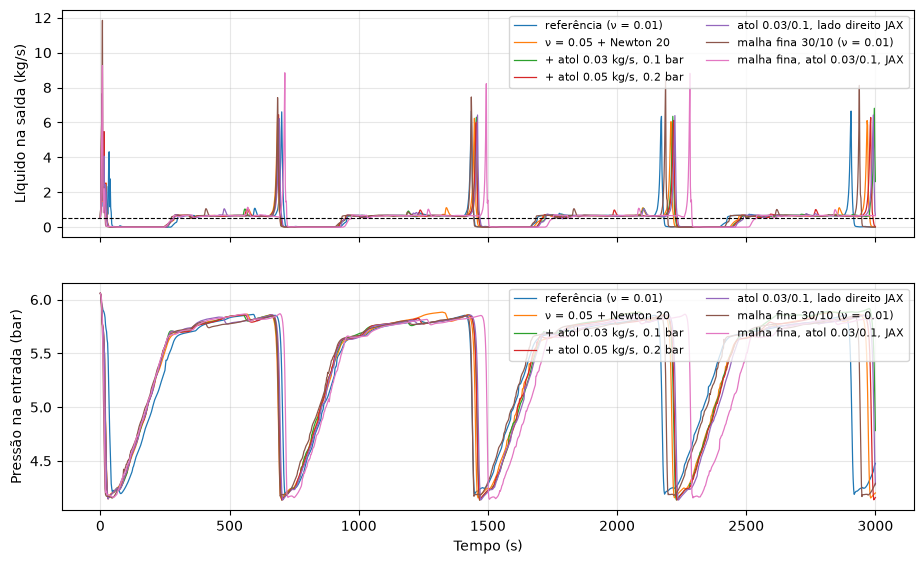

configuração                     passos     CPU blowdowns  período  pico máx   P_in (bar)  erro massa L
referência (ν = 0.01)             85653    20 min         5    710 s    6.7 kg/s  4.19–5.86     -5.1e-06 kg
ν = 0.05 + Newton 20              59236    14 min         5    738 s    6.4 kg/s  4.15–5.88     -2.0e-06 kg
+ atol 0.03 kg/s, 0.1 bar         23172     5 min         4    733 s    6.8 kg/s  4.13–5.92     -4.6e-04 kg
+ atol 0.05 kg/s, 0.2 bar         21798     5 min         5    741 s    6.4 kg/s  4.14–5.86     -9.7e-04 kg
atol 0.03/0.1, lado direito JAX    22618     1 min         5    742 s    6.4 kg/s  4.14–5.86     -2.8e-04 kg
malha fina 30/10 (ν = 0.01)      201553    58 min         5    726 s    8.6 kg/s  4.17–5.85     -9.5e-06 kg
malha fina, atol 0.03/0.1, JAX    39033     2 min         4    747 s    8.8 kg/s  4.14–5.87     -3.6e-04 kg


In [24]:
if runs_fast:
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    for k, (tag, r) in enumerate(runs_fast.items()):
        T_, p_ = r["T"], r["p"]
        axes[0].plot(T_, p_["out"]["qL"][-1], lw=0.9, label=tag)
        axes[1].plot(T_, p_["out"]["P_bar"][1], lw=0.9, label=tag)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8); axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)"); axes[1].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper right", ncol=2)
    plt.show()
    print(f"{'configuração':30s} {'passos':>8s} {'CPU':>7s} {'blowdowns':>9s} {'período':>8s} {'pico máx':>9s} {'P_in (bar)':>12s} {'erro massa L':>13s}")
    for tag, r in runs_fast.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        massL, _, _ = r["balL"]; eL = (massL[-1] - massL[0] - r["acc"][0, -1]) if r["acc"] is not None else np.nan
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(f"{tag:30s} {r['meta']['n_steps']:8d} {r['meta']['cpu']/60:5.0f} min {nb_:9d} {per:6.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f} {eL:+12.1e} kg")

## Rede de dutos acoplados por vértices em vez de um duto único curvado

O mesmo caso montado como **rede**: linha (horizontal + descendente), pescoço (o
arco, como duto próprio), riser e horizontal de saída, ligados por três vértices
dinâmicos (balanço de massa num volume V, sem momento; o vértice impõe αG e P na
entrada do duto a jusante e P na saída do duto a montante). A condição inicial
bloqueada é a mesma do duto único, interpolada pelos dutos, e os vértices partem do
estado da junção. O volume do vértice é o parâmetro que não existe no duto único:
um volume grande acrescenta estoque e amortece; um volume pequeno torna o vértice
rígido (a pressão responde ao desbalanço de vazões com constante de tempo V·C).
Comparação com o duto único curvado (mesma malha, formulação conservativa, ν =
0.05, JAX, `tol_range` 0.01).

In [25]:
runs_net = {}
for tag, fname in (("duto único curvado", "severe_slug_blocked_conservative_arc_tol.npz"),
                   ("rede, V = 0.05 m³", "severe_slug_blocked_network_v050.npz"),
                   ("rede, V = 0.005 m³", "severe_slug_blocked_network_v005.npz"),
                   ("rede, V = 0.002 m³", "severe_slug_blocked_network_v002.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs_net[tag] = load_blocked_run(f)

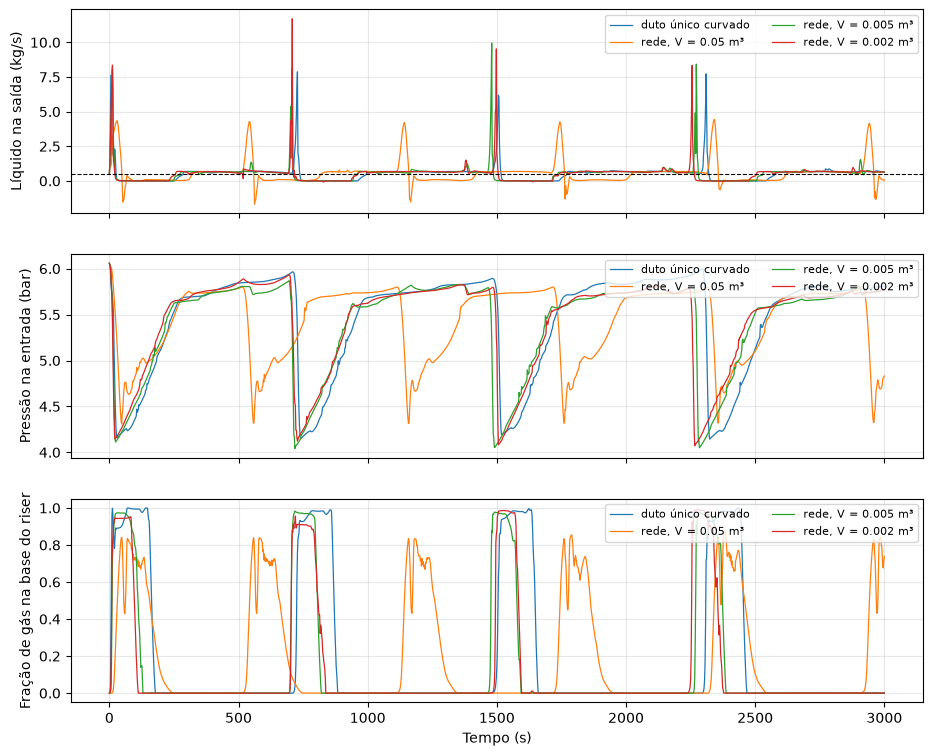

configuração           estados   passos    CPU blowdowns intervalo  pico máx   P_in (bar)
duto único curvado         112    25923    50 s         4     765 s    7.9 kg/s  4.14–6.00
rede, V = 0.05 m³          124    35518   148 s         6     582 s    4.4 kg/s  4.32–5.80
rede, V = 0.005 m³         124    61109   221 s         4     753 s   10.0 kg/s  4.04–5.87
rede, V = 0.002 m³         124    65018   225 s         4     748 s   11.7 kg/s  4.07–5.94


In [26]:
if runs_net:
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    for k, (tag, r) in enumerate(runs_net.items()):
        T_ = r["T"]
        axes[0].plot(T_, r["p_last"]["out"]["qL"][-1], lw=0.9, label=tag)
        axes[1].plot(T_, r["p"]["out"]["P_bar"][1], lw=0.9, label=tag)
        axes[2].plot(T_, r["aG_riser_base"], lw=0.9, label=tag)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8); axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)"); axes[2].set_ylabel("Fração de gás na base do riser"); axes[2].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper right", ncol=2)
    plt.show()
    print(f"{'configuração':22s} {'estados':>7s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s}")
    for tag, r in runs_net.items():
        T_, q_ = r["T"], r["p_last"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(f"{tag:22s} {r['model'].n_states:7d} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f}")

## Identificação automática do padrão de escoamento (regime 6)

Até aqui o padrão foi prescrito: estratificado na linha e bolhas no riser, com a
mistura suave por ângulo no joelho. A tese tem uma identificação automática
(`identificaRegimeEstavel.m`): frações de equilíbrio de Taitel–Dukler
(estratificado) e Pots (anular) obtidas por busca em tabela, critérios de
Kelvin–Helmholtz, Jeffreys, Froude e turbulência, e indicadores com chaveamento
sigmoidal de inclinação `k_switch` = 1e6 (degraus). Ela foi portada para JAX
(`closures.regime.equilibrium_fractions`/`identify_regime` com `bk=JAX`, reprodução a 1e−14,
Jacobiana exata) e aplicada ao severe slug.

**O IPE da tese não funciona em dinâmica tal como está.** Nos estados gravados da
corrida de referência ele dá estratificado na linha descendente, intermitente no
trecho horizontal de entrada (a 4 % do limiar de Kelvin–Helmholtz) e "anular" no
riser cheio de líquido (equilíbrio de Pots degenerado com vGS → 0). Na partida
bloqueada o integrador rasteja (9834 passos até 1.5 s; padrão fixo: 101 até 2 s),
por quatro razões, localizadas com saída densa de 1 ms:

1. células cheias de líquido: FG* = FG*c = 0 → sigmoide(0) = 0.5 permanente, e a
   fórmula Int = (1−Est)(1−Anu)(1−Bub) não é partição da unidade (soma 1.44);
2. o gás da entrada inverte o sentido no toque acústico da partida (vGS de +0.5 a
   −0.7 m/s em 0.5 s): com vGS < 0 os equilíbrios dão NaN e o original cai em
   hD = 1e−6 → FG*c salta de 0.02 a 19.8; sign(vM) e aG_bol saltam junto → pesos
   de 0 a 1 em 1 ms, qualquer que seja k;
3. a tabela "mais próxima" muda hD_est em degraus de 2–5 %;
4. `flag_vertical` comparava radianos com 90 (nunca vertical).

**Correções e opções** (numpy e JAX): indicador vertical em graus e partição da
unidade (sem efeito com indicadores 0/1); `low_void_regime` também no modo
automático (bolhas abaixo de 1 %: sem gás não há padrão a identificar);
`ipe_smooth=True`: sigmoides de largura relativa ao valor crítico (`k_switch` ≈ 20,
±10 % do limiar), equilíbrios com |vLS|, |vGS|, hD interpolado na tabela
(contínuo), sentido por tanh(vM/0.02) e aG_bol com módulos. Até 10 s: 170 passos
(k = 20), 427 (k = 50), 370 com padrão fixo. Mas o primeiro *blowdown* continua
caro (13458 passos até 101 s): depois dele fica um bolsão quase parado no joelho
(αG = 0.8, vLS ≈ 0) e o mapa de regime permanente, que só olha velocidades
superficiais, chama-o de "bolhas" sempre que a velocidade do gás, que toca a
~30 Hz, cai; o fechamento alterna bolhas ↔ intermitente a cada 16 ms e sustenta o
toque. `ipe_local=True` avalia os critérios no estado local: nível e fração reais
no lugar dos equilíbrios, fração de bolhas max(aG_bol, αG), estratificado
impossível em dutos verticais e anular acima de αG = 0.9 (filme de parede):
986 passos até 101 s, sem saltos de peso. Abaixo, as corridas completas (3000 s,
mesma malha, arco, conservativa, ν = 0.05, JAX, `tol_range` 0.01) comparadas com
o padrão fixo, e o mapa do padrão identificado ao longo do duto e do tempo.

Resultado: as três variantes do IPE dão o mesmo ciclo de intermitência severa
(4 blowdowns, intervalo 851–883 s contra 765 s com padrão fixo, pressão de
entrada 4.0–5.9 bar nos dois casos, produção média 0.49–0.50 kg/s para
alimentação 0.53), com picos de líquido menores e mais largos (4–5.7 kg/s contra
7.9): no blowdown o riser é identificado como intermitente → anular, com mais
atrito interfacial do que o padrão de bolhas prescrito. O custo é a diferença:
o modo local gasta 35k passos / 207 s de CPU; só o modo suave 163–176k passos /
~32 min (fase rápida a alternar bolhas ↔ intermitente no bolsão do joelho); o
modo da tese (k = 1e6) não passa de t ≈ 2 s. O padrão fixo gasta 26k passos /
50 s (o IPE custa ~3× por passo pelas tabelas de equilíbrio).

In [27]:
from mfsim.closures import identify_regime, equilibrium_fractions

runs_ipe = {}
for tag, fname in (("padrão fixo (estratificado + bolhas no riser)", "severe_slug_blocked_conservative_arc_tol.npz"),
                   ("IPE suave (k = 20, bolhas < 1 %)", "severe_slug_blocked_regime6_smooth.npz"),
                   ("IPE suave (k = 50, bolhas < 1 %)", "severe_slug_blocked_regime6_smooth_k50.npz"),
                   ("IPE suave + critérios no estado local (k = 20)", "severe_slug_blocked_regime6_local.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs_ipe[tag] = load_blocked_run(f)


def regime_map(r, step=2):
    """reg2 (1 anular, 2 bolhas, 3 intermitente, 4/5 estratificado) em cada nó e instante gravado."""
    pb_ = r["model"].pipes[0]; sch_ = pb_.scheme; mod_ = pb_.model
    T_ = r["T"][::step]; Ys = r["p"]["Y"][::step]
    reg = np.empty((Ys.shape[1], T_.size))
    for j, Y_ in enumerate(Ys):
        inp_, _, _ = mod_.local_state(Y_, sch_.theta_nodes)
        p_ = mod_.params
        fl_, _ = identify_regime(inp_, k_switch=p_.k_switch, eq=equilibrium_fractions(inp_, smooth=p_.ipe_smooth), smooth=p_.ipe_smooth, local=p_.ipe_local)
        reg[:, j] = fl_.reg2
    return T_, sch_.x_nodes, reg

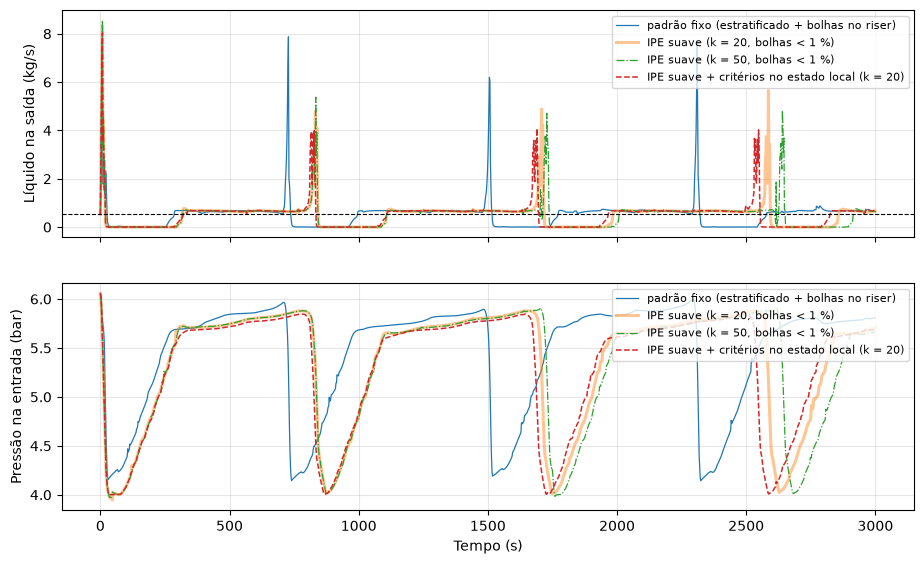

configuração                                     passos    CPU blowdowns intervalo  pico máx   P_in (bar)  erro massa L
padrão fixo (estratificado + bolhas no riser)     25923    50 s         4     765 s    7.9 kg/s  4.14–6.00     +4.3e-05 kg
IPE suave (k = 20, bolhas < 1 %)                 175927  2034 s         4     861 s    5.7 kg/s  4.01–5.88     -2.4e-03 kg
IPE suave (k = 50, bolhas < 1 %)                 163091  1892 s         4     883 s    5.4 kg/s  3.98–5.91     -9.0e-04 kg
IPE suave + critérios no estado local (k = 20)    35328   207 s         4     851 s    4.1 kg/s  4.01–5.86     -2.3e-02 kg


In [28]:
if runs_ipe:
    # estilos distintos: as variantes com k = 20 (suave e suave + local) quase coincidem até o 3º blowdown
    styles = [dict(lw=0.9), dict(lw=2.2, alpha=0.45), dict(lw=0.9, ls="-."), dict(lw=1.1, ls="--")]
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    for (tag, r), st in zip(runs_ipe.items(), styles):
        T_, p_ = r["T"], r["p"]
        axes[0].plot(T_, p_["out"]["qL"][-1], label=tag, **st)
        axes[1].plot(T_, p_["out"]["P_bar"][1], label=tag, **st)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8); axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)"); axes[1].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper right")
    plt.show()
    print(f"{'configuração':46s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s} {'erro massa L':>13s}")
    for tag, r in runs_ipe.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        massL, _, _ = r["balL"]; eL = (massL[-1] - massL[0] - r["acc"][0, -1]) if r["acc"] is not None else np.nan
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(f"{tag:46s} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f} {eL:+12.1e} kg")

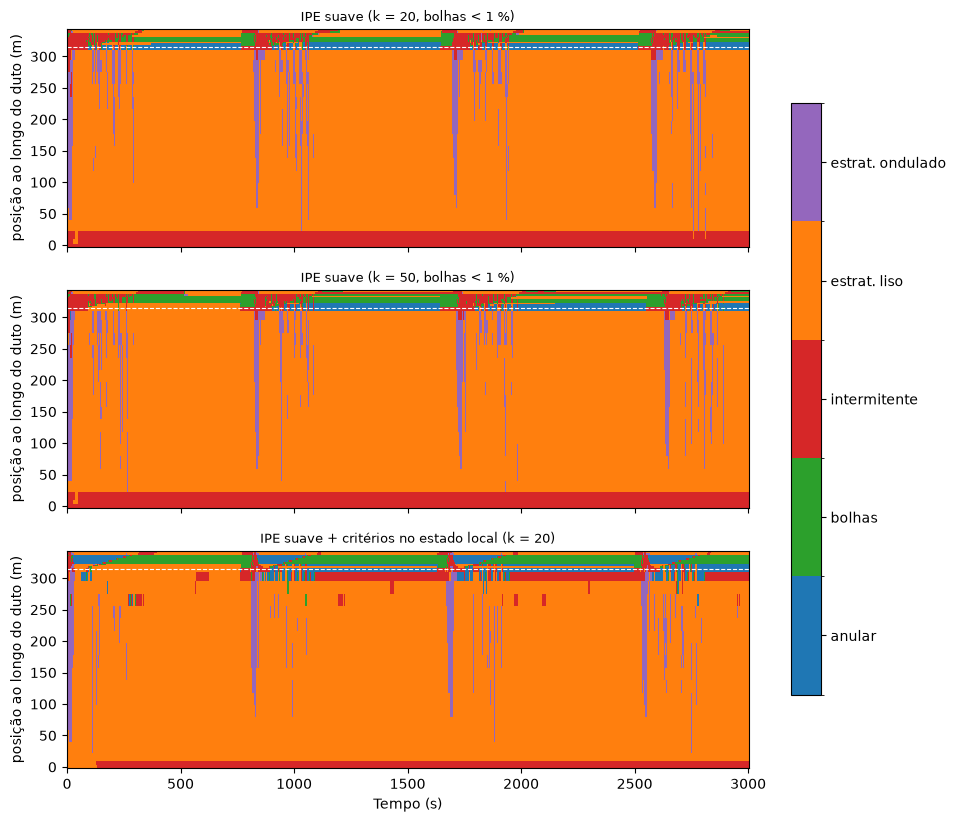

In [29]:
from matplotlib.colors import ListedColormap, BoundaryNorm
ipe_runs = [(t, r) for t, r in runs_ipe.items() if r["meta"].get("regime", 4) == 6]
if ipe_runs:
    cmap = ListedColormap(["#1f77b4", "#2ca02c", "#d62728", "#ff7f0e", "#9467bd"]); norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)
    fig, axes = plt.subplots(len(ipe_runs), 1, figsize=(11, 3.2 * len(ipe_runs)), sharex=True, squeeze=False)
    for ax, (tag, r) in zip(axes[:, 0], ipe_runs):
        T_, x_, reg = regime_map(r)
        pc = ax.pcolormesh(T_, x_, reg, cmap=cmap, norm=norm, shading="nearest")
        ax.axhline(r["case"].meta["s_elbow0"], color="w", lw=0.8, ls="--")
        ax.set_ylabel("posição ao longo do duto (m)"); ax.set_title(tag, fontsize=9)
    axes[-1, 0].set_xlabel("Tempo (s)")
    cb = fig.colorbar(pc, ax=axes, ticks=[1, 2, 3, 4, 5], shrink=0.8); cb.ax.set_yticklabels(["anular", "bolhas", "intermitente", "estrat. liso", "estrat. ondulado"])
    plt.show()

## Reconstrução de α nas faces e o arrasto espúrio da fase virtual

Dois temas levantados na lista de pendências. **(1) Reconstrução MUSCL/TVD da
fração de área nas faces** (`alpha_face="muscl"`: declive minmod a partir da
célula doadora, numpy e JAX) para ganhar nitidez da frente sem refinar a malha.
No esquema escalonado as vazões das faces são estados e os fluxos de massa são
essas vazões (limitadas pela célula doadora); a fração nas faces só entra na
equação de momento (gradiente de pressão, gravidade, velocidades). Resultado na
malha grossa: ciclo igual (intervalo 775 s contra 765 s, P_in 4.12–6.04) e a
largura mediana da frente de gás no riser (transição 0.1–0.9 de αG) fica em 2.9 m
nas duas variantes, contra 1.7 m na malha fina: a difusão da frente vem da
dinâmica do momento (velocidade doadora de 1ª ordem, relaxação da fase ausente,
limitador), não da interpolação de α; o MUSCL em α não é uma alavanca de nitidez.

**(2) Excitação do modo acústico do tampão.** Experimento controlado: coluna de
20 m (20 células) entre duas extremidades, com (B) líquido monofásico, (A') o modelo
a dois fluidos com a coluna cheia de líquido (αG = 0) e (A) um tampão de 12 m entre
dois bolsões de gás (αG = 0.7). Com um degrau de pressão entre pressões fixas, a
coluna monofásica acelera livremente (3.6 kg/s em 3 s) e a coluna do modelo a dois
fluidos com fechamento estratificado **trava em 0.49 kg/s**: a decomposição do
balanço de momento mostra GammaL = 1.96 N/m contra 0.05 N/m de atrito de parede. É
a **força interfacial com a camada de gás virtual** (αG cortado em 1e−3) que a
relaxação da fase ausente mantém parada (o alvo de vazão usa a fração REAL, nula):
a 0.27 m/s o estratificado exerce 40× o atrito de parede, a 1 m/s 58× (anular 8–10×;
bolhas e intermitente nada). Com o gás virtual acompanhando o líquido (vG = vL) todos
os fechamentos reproduzem o monofásico. Daí a opção `relax_target="noslip"`
(alvo sem escorregamento com a fração da célula doadora com piso em `alpha_min`, nas
duas fases; só no modo conservativo, onde o limitador de fluxo impede que a vazão
virtual drene massa): a coluna volta a 3.65 kg/s e o decaimento do modo acústico
fechado passa de 1.33 para 0.63 1/s (monofásico 0.32). Uma primeira versão usou a
fração média da face em vez da doadora e fazia o severe slug rastejar: numa face
entre uma célula cheia de gás e outra com 13 % de gás o filme de 1 % era arrastado
como se fosse 44 % do tubo, à velocidade do gás do blowdown. Conclusão para a pergunta original: as células cheias de líquido do
modelo a dois fluidos não excitam o modo do tampão; são **mais amortecidas** do que o
monofásico por um arrasto espúrio, que liga e desliga nas células onde a fração
cruza a banda da relaxação. No severe slug de referência (tabela abaixo) a variante
`noslip` (ver tabela) custa o mesmo, mantém o ciclo (intervalo 749 s contra 765)
e baixa a pressão máxima de entrada de 6.00 para 5.92 bar e os picos de 7.9 para
7.1 kg/s. É a variante fisicamente consistente; os resultados anteriores devem
ser lidos com essa ressalva.

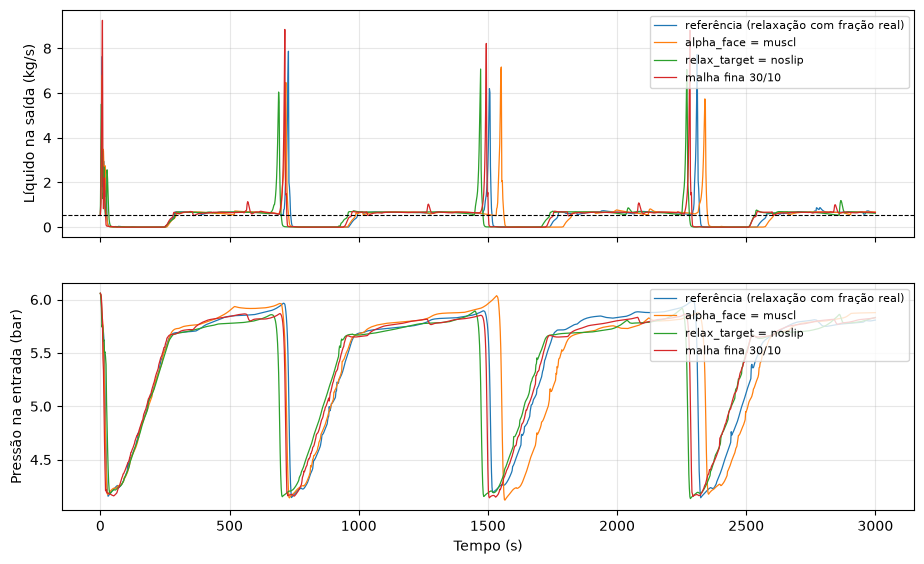

configuração                               passos    CPU blowdowns intervalo  pico máx   P_in (bar) frente 0.1-0.9
referência (relaxação com fração real)      25923    50 s         4     765 s    7.9 kg/s  4.14–6.00        2.9 m
alpha_face = muscl                          24788    48 s         4     775 s    7.2 kg/s  4.12–6.04        2.9 m
relax_target = noslip                       25228    47 s         4     749 s    7.1 kg/s  4.14–5.92        2.9 m
malha fina 30/10                            39033   105 s         4     747 s    8.8 kg/s  4.14–5.87        1.7 m


In [30]:
runs_ns = {}
for tag, fname in (("referência (relaxação com fração real)", "severe_slug_blocked_conservative_arc_tol.npz"),
                   ("alpha_face = muscl", "severe_slug_blocked_conservative_arc_tol_muscl.npz"),
                   ("relax_target = noslip", "severe_slug_blocked_conservative_arc_tol_noslip.npz"),
                   ("malha fina 30/10", "severe_slug_blocked_conservative_arc_fine_fast1_jax.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs_ns[tag] = load_blocked_run(f)


def front_width(r):
    """Largura mediana (m) da transição 0.1-0.9 de alphaG no riser nos instantes com gás no riser."""
    x_ = r["p"]["x"]; aG_ = r["p"]["out"]["alphaG"]; ib_ = r["ib"]; w = []
    for it in range(r["T"].size):
        seg = aG_[ib_:, it]; xs = x_[ib_:]
        if seg.max() > 0.5 and seg.min() < 0.05:
            j1 = np.argmax(seg > 0.1); j9 = np.argmax(seg > 0.9) if (seg > 0.9).any() else len(seg) - 1
            if j9 > j1: w.append(xs[j9] - xs[j1])
    return float(np.median(w)) if w else np.nan


if runs_ns:
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    for tag, r in runs_ns.items():
        axes[0].plot(r["T"], r["p"]["out"]["qL"][-1], lw=0.9, label=tag)
        axes[1].plot(r["T"], r["p"]["out"]["P_bar"][1], lw=0.9, label=tag)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8); axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)"); axes[1].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper right")
    plt.show()
    print(f"{'configuração':40s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s} {'frente 0.1-0.9':>14s}")
    for tag, r in runs_ns.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(f"{tag:40s} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f} {front_width(r):10.1f} m")

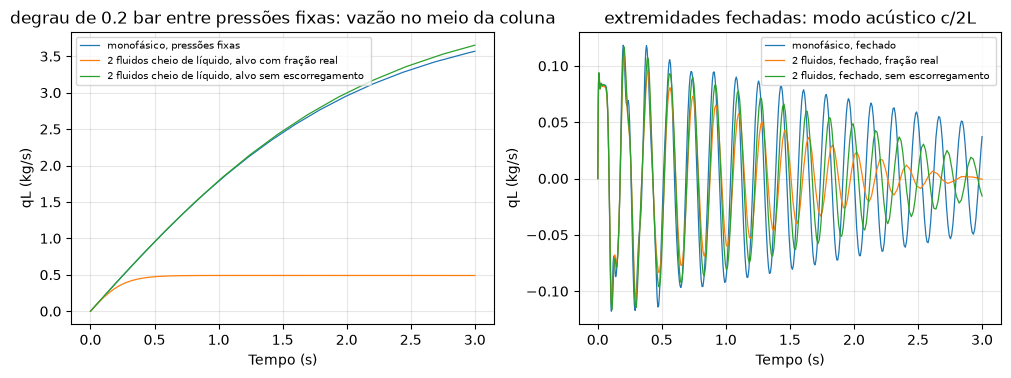

caso                                                 passos  q final  f (Hz)  decaimento (1/s)
monofásico, pressões fixas                               26    3.568     nan               nan
2 fluidos cheio de líquido, alvo com fração real         27    0.490     nan               nan
2 fluidos cheio de líquido, alvo sem escorregamento      23    3.651     nan               nan
monofásico, fechado                                     406    0.037    5.56              0.32
2 fluidos, fechado, fração real                         240   -0.001    5.56              1.33
2 fluidos, fechado, sem escorregamento                  294   -0.015    5.56              0.63


In [31]:
from mfsim.network.data import BC_ABSENT, BC_DIRICHLET, BC_NEUMANN, Case, Pipe, SimulatorSettings, Vertex
from mfsim.integrators.implicit import ImplicitBDF
from mfsim.compiled import build_jax_rhs
from mfsim.simulation import state_bounds


def column_case(which, closed=False, relax_target="raw", L_=20.0, N_=20, dP_=0.2e5, tf_=3.0, dt_=1e-3):
    """Coluna de L_ m entre dois vértices: B = líquido monofásico; Ap = dois fluidos cheia de líquido;
    A = tampão entre bolsões de gás (4 m, alphaG 0.7). Degrau de pressão inicial (pressões fixas nas
    extremidades, ou extremidades fechadas com degrau no meio)."""
    P0_ = 5e5; xn = np.linspace(0, L_, N_ + 1); ic_ = np.zeros((N_ + 1, 4))
    ic_[:, 1] = (P0_ + dP_ * (xn < L_ / 2)) / 1e6 if closed else (P0_ + dP_ * (1 - xn / L_)) / 1e6
    if closed:
        verts = [Vertex(index=1, kind="B", spec={"qL": 0.0, "qG": 0.0}), Vertex(index=2, kind="B", spec={"qL": 0.0, "qG": 0.0})]
    else:
        verts = [Vertex(index=1, kind="B", spec={"PT": (P0_ + dP_) / 1e6}), Vertex(index=2, kind="B", spec={"PT": P0_ / 1e6})]
    if which == "B":
        mid, ex = 3, {"q_switch": 1e-3}
        bci = (BC_ABSENT, BC_ABSENT, BC_DIRICHLET, BC_ABSENT) if closed else (BC_ABSENT, BC_DIRICHLET, BC_ABSENT, BC_ABSENT)
        bco = bci
    else:
        mid = 1
        if which == "A":
            ic_[:, 0] = np.where((xn < 4.0) | (xn > L_ - 4.0), 0.7, 0.0)
        ex = {"regime_vertical": 0, "q_switch_L": 1e-3, "q_switch_G": 1e-5, "switch_frac": 0.5, "conservative": True, "relax_target": relax_target}
        bci = (BC_NEUMANN, BC_ABSENT, BC_DIRICHLET, BC_DIRICHLET) if closed else (BC_NEUMANN, BC_DIRICHLET, BC_ABSENT, BC_ABSENT)
        bco = (BC_ABSENT, BC_ABSENT, BC_DIRICHLET, BC_DIRICHLET) if closed else (BC_ABSENT, BC_DIRICHLET, BC_ABSENT, BC_ABSENT)
    st = SimulatorSettings(t0=0.0, tf=tf_, dt_out=dt_, PR=1e6, method="fv_upwind", max_step=np.inf, atol=1e-6, rtol=3e-3, quadrature_order=2, integrator="implicit")
    pipe_ = Pipe(index=1, v_in=1, v_out=2, x=[0.0, 0.0], y=[0.0, L_], z=[0.0, 0.0], n_elements=[N_], D=D, roughness=1e-5, model=mid, regime=4, bc_in=bci, bc_out=bco, ic=ic_, extra=ex)
    return Case(name="coluna", fluid=fluid, settings=st, vertices=verts, pipes=[pipe_])


def run_column(case_):
    m_ = build_model(case_); X0_ = m_.initial_state(); rhs_, jac_ = build_jax_rhs(m_)
    lo_, hi_ = state_bounds(m_); kw_ = dict(transform=m_.transform, inverse=m_.inverse_transform, transform_jac=m_.transform_jacobian) if m_.conservative else {}
    bdf_ = ImplicitBDF(rhs_, S=m_.jac_sparsity(), rtol=3e-3, atol=1e-3 * np.ones(X0_.size), bounds=(lo_, hi_), jac_fun=jac_, min_step=1e-9, verbose=False, max_order=2, max_newton=20, newton_tol=1e-3, **kw_)
    bdf_.slow_exit = False
    st = case_.settings; T_, X_, info_ = bdf_.integrate(np.arange(0, st.tf + 0.5 * st.dt_out, st.dt_out), X0_, first_step=1e-4)
    X_ = np.asarray(X_); X_ = X_.T if X_.shape[0] != T_.size else X_
    N_ = m_.pipes[0].scheme.N
    q_mid = np.array([m_.assemble(0.0, X_[i])[1][0][N_ // 2, 2] for i in range(T_.size)])
    return T_, q_mid, info_


def decay_rate(T_, q_, t_skip=0.3):
    from scipy.signal import find_peaks
    sel = T_ > t_skip; qq = q_[sel] - q_[sel].mean(); tt = T_[sel]
    f_ = np.fft.rfftfreq(qq.size, T_[1] - T_[0]); s_ = np.abs(np.fft.rfft(qq * np.hanning(qq.size))); f_dom = f_[np.argmax(s_[1:]) + 1]
    pk, _ = find_peaks(np.abs(qq), distance=max(1, int(0.5 / f_dom / (T_[1] - T_[0]))))
    rate = -np.polyfit(tt[pk], np.log(np.abs(qq[pk])), 1)[0] if pk.size > 4 else np.nan
    return f_dom, rate


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rows = []
for which, closed, rt, lab in (("B", False, "raw", "monofásico, pressões fixas"), ("Ap", False, "raw", "2 fluidos cheio de líquido, alvo com fração real"),
                               ("Ap", False, "noslip", "2 fluidos cheio de líquido, alvo sem escorregamento "),
                               ("B", True, "raw", "monofásico, fechado"), ("Ap", True, "raw", "2 fluidos, fechado, fração real"), ("Ap", True, "noslip", "2 fluidos, fechado, sem escorregamento ")):
    T_, q_, info_ = run_column(column_case(which, closed=closed, relax_target=rt))
    ax = axes[1 if closed else 0]; ax.plot(T_, q_, lw=0.9, label=lab)
    f_dom, rate = decay_rate(T_, q_) if closed else (np.nan, np.nan)
    rows.append((lab, info_["n_steps"], q_[-1], f_dom, rate))
axes[0].set_title("degrau de 0.2 bar entre pressões fixas: vazão no meio da coluna"); axes[1].set_title("extremidades fechadas: modo acústico c/2L")
for ax in axes:
    ax.set_xlabel("Tempo (s)"); ax.set_ylabel("qL (kg/s)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.show()
print(f"{'caso':52s} {'passos':>6s} {'q final':>8s} {'f (Hz)':>7s} {'decaimento (1/s)':>17s}")
for lab, n_, qf, f_dom, rate in rows:
    print(f"{lab:52s} {n_:6d} {qf:8.3f} {f_dom:7.2f} {rate:17.2f}")

## Severe slug com o modelo de deriva (Beggs & Brill)?

Com o volume finito escalonado estendido ao modelo de deriva (ver o notebook do
poço 10.3.1: hold-up e pressão nas células, vazões nas faces, momento da mistura e
a relação de escorregamento imposta na forma diferenciada) o caso pode ser montado
com `severe_slug_case(model=2)`. Não é simulável com esta correlação, e o motivo é
físico: partindo da condição bloqueada (bolsão com 75 % de gás sobre líquido a
0.3 m/s, riser cheio) a restrição de escorregamento exige vazões de gás de vários
m/s para que a correlação "explique" 75 % de gás com esse líquido; aparece uma
recirculação de ±6 kg/s nas faces da entrada e o integrador para em t ≈ 2.3 s, com
derivadas exatas ou por diferenças finitas. Um bolsão parado sobre líquido em
movimento (escorregamento infinito) não é um estado de uma correlação ajustada em
escoamento co-corrente permanente. Partindo do hold-up da própria correlação
(`ic_holdup="correlation"`) a mesma geometria vai para um estado estacionário em
157 passos (P_in 4.66 bar, produção igual à alimentação, 20–30 % de gás no riser):
a correlação amarra a vazão de gás à do líquido e não há mecanismo de bloqueio do
gás pela coluna de líquido, que é o que gera o ciclo. Para ter severe slug com um
modelo de deriva seria preciso uma lei de escorregamento em velocidade
(vG = C0·vM + vd) que admita gás parado com líquido em movimento.

### Fronteira de Bøe e o fechamento do riser

Critério de Bøe (1981), na forma citada por Taitel (1986) e Jansen et al. (1996):
há intermitência severa se vSL ≥ vSL_mín = P_base·vSG / (ρL g (1 − αG) L), com L o
comprimento de linha ocupado pelo gás e **sem** fator de inclinação. (Correção de
2026-10-13: a versão anterior desta análise dividia L por sin|θ|, o que não consta das
fontes e dava vSL_mín = 1.03 m/s para o caso base; o valor correto é 0.06 m/s.) Com a
forma correta **todos** os pontos simulados estão dentro da região de Bøe, inclusive o
caso base (vSL = 0.30 ≫ 0.06): o ciclo com bolhas no riser é coerente com Bøe, e a
ausência de ciclo com intermitente no riser no caso base é uma sensibilidade do modelo ao
fechamento do riser, não uma previsão do critério. Acima de 1.2 m/s os dois fechamentos
dão escoamento permanente porque a linha deixa de ser estratificada (Taitel 1986 exige as
duas condições). O caso de linha longa (1000 m, 2 bar) cicla com bolhas e com intermitente:
aí os dois fechamentos dão o ciclo clássico (pressurização lenta da linha com o riser
cheio de líquido, blowdown, reenchimento), com período 3850–4280 s (±10 %) e picos de
7.8–8.9 kg/s. O caso base é um caso de fronteira, dependente do fechamento a baixa
fração de gás no riser; o de linha longa demonstra o mecanismo de forma robusta.
(O intermitente sem as regras físicas não passa da partida neste caso: blowdown
inicial violento com 0.3 bar de sobrepressão, rastejo no riser cheio de líquido com 0.1.)

In [32]:
from mfsim.cases.severe_slug import boe_criterion
runs_boe = {}
for tag, fname in (("caso base, bolhas no riser", "severe_slug_blocked_conservative_arc_tol_noslip.npz"),
                   ("caso base, intermitente no riser", "severe_slug_blocked_conservative_arc_tol_int.npz"),
                   ("vSL = 1.2, bolhas", "severe_slug_blocked_conservative_arc_tol_v12_bub.npz"),
                   ("vSL = 1.2, intermitente", "severe_slug_blocked_conservative_arc_tol_v12_int.npz"),
                   ("vSL = 1.6, bolhas", "severe_slug_blocked_conservative_arc_tol_v16_bub.npz"),
                   ("vSL = 1.6, intermitente", "severe_slug_blocked_conservative_arc_tol_v16_int.npz"),
                   ("L = 1000 m, 2 bar, bolhas", "severe_slug_blocked_conservative_arc_boe_bub.npz"),
                   ("L = 1000 m, 2 bar, bolhas, sobrepressão 0.1 bar", "severe_slug_blocked_conservative_arc_boe_bub_dp01.npz"),
                   ("L = 1000 m, 2 bar, bolhas + regras físicas", "severe_slug_blocked_conservative_arc_boe_bub_rules.npz"),
                   ("L = 1000 m, 2 bar, intermitente + regras físicas", "severe_slug_blocked_conservative_arc_boe_int_rules.npz"),
                   ("L = 1000 m, 2 bar, vSL = 0.5, regras", "severe_slug_blocked_conservative_arc_scan_P2_v05.npz"),
                   ("L = 1000 m, 2 bar, vSL = 0.8, regras", "severe_slug_blocked_conservative_arc_scan_P2_v08.npz"),
                   ("L = 1000 m, 4 bar, vSL = 0.5, regras", "severe_slug_blocked_conservative_arc_scan_P4_v05.npz"),
                   ("L = 1000 m, 4 bar, vSL = 0.8, regras", "severe_slug_blocked_conservative_arc_scan_P4_v08.npz"),
                   ("L = 1000 m, 2 bar, vSL = 0.15, regras", "severe_slug_blocked_conservative_arc_scan_P2_v015.npz"),
                   ("L = 1000 m, 2 bar, vSL = 0.3, regras", "severe_slug_blocked_conservative_arc_scan_P2_v03.npz"),
                   ("L = 1000 m, 4 bar, vSL = 0.3, regras", "severe_slug_blocked_conservative_arc_scan_P4_v03.npz"),
                   ("L = 1000 m, 2 bar, vSG = 0.05, regras", "severe_slug_blocked_conservative_arc_scan_P2_g005.npz"),
                   ("L = 1000 m, 2 bar, vSG = 0.2, regras", "severe_slug_blocked_conservative_arc_scan_P2_g02.npz"),
                   ("L = 1000 m, 2 bar, 2 m³ a montante (vértice), regras", "severe_slug_blocked_conservative_arc_boe_vup20.npz"),
                   ("L = 1000 m, 2 bar, vSG = 0.2, intermitente + regras", "severe_slug_blocked_conservative_arc_scan_P2_g02_int.npz"),
                   ("caso base + 200 m de linha de entrada, regras", "severe_slug_blocked_conservative_arc_tol_lh1_200.npz"),
                   ("caso base + 500 m de linha de entrada, regras", "severe_slug_blocked_conservative_arc_tol_lh1_500.npz"),
                   ("L = 1000 m, 2 bar, γG = 1.3, regras", "severe_slug_blocked_conservative_arc_scan_P2_v03_gammaG13.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    r_ = load_blocked_run(f); mb = r_["meta"]      # P_in pelo Results (o índice do estado muda com vértice a montante)
    T_ = r_["T"]; P1 = r_["p"]["out"]["P_bar"][1]; sel = T_ > 300
    P_base = mb.get("P_out", 4.0) * 1e5 + fluid.rhoL0 * 9.81 * mb.get("H_riser", 20.0)
    # a alimentação de gás é definida a P_out + 1 bar (severe_D.py); vSG à pressão do separador
    vSG_ = mb.get("vSG", 0.1) * fluid.rhoG((mb.get("P_out", 4.0) + 1.0) * 1e5) / fluid.rhoG(mb.get("P_out", 4.0) * 1e5)
    vmin, severe = boe_criterion(mb.get("vSL", 0.3), vSG_, P_base, fluid.rhoL0, 0.5, mb.get("L_h1", 20.0) + mb.get("L_down", 300.0))   # L de gás = linha de entrada + descendente
    amp = P1[sel].max() - P1[sel].min()
    tb = blowdowns(T_[sel], P1[sel]) if amp > 0.3 else np.array([])      # sem oscilação de pressão não há blowdown
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    runs_boe[tag] = dict(vSL=mb.get("vSL", 0.3), L=mb.get("L_down", 300.0), P=mb.get("P_out", 4.0), vmin=vmin, n_steps=mb["n_steps"], amp=P1[sel].max() - P1[sel].min(), nb=tb.size, per=per)
if runs_boe:
    print(f"{'caso':34s} {'vSL':>5s} {'L (m)':>6s} {'P_out':>6s} {'vSL_mín Bøe':>12s} {'passos':>7s} {'ΔP_in (t>300 s)':>16s} {'blowdowns':>9s} {'intervalo':>9s}")
    for tag, r in runs_boe.items():
        print(f"{tag:34s} {r['vSL']:5.2f} {r['L']:6.0f} {r['P']:6.1f} {r['vmin']:12.3f} {r['n_steps']:7d} {r['amp']:12.2f} bar {r['nb']:9d} {r['per']:7.0f} s")

caso                                 vSL  L (m)  P_out  vSL_mín Bøe  passos  ΔP_in (t>300 s) blowdowns intervalo
caso base, bolhas no riser          0.30    300    4.0        0.050   25228         1.78 bar         3     790 s
caso base, intermitente no riser    0.30    300    4.0        0.050  101181         0.23 bar         0     nan s
vSL = 1.2, bolhas                   1.20    300    4.0        0.050     555         0.04 bar         0     nan s
vSL = 1.2, intermitente             1.20    300    4.0        0.050    1123         0.00 bar         0     nan s
vSL = 1.6, bolhas                   1.60    300    4.0        0.050     356         0.03 bar         0     nan s
vSL = 1.6, intermitente             1.60    300    4.0        0.050    3325         0.03 bar         0     nan s
L = 1000 m, 2 bar, bolhas           0.30   1000    2.0        0.012  105019         1.68 bar         2    3750 s
L = 1000 m, 2 bar, bolhas, sobrepressão 0.1 bar  0.30   1000    2.0        0.012   63993        

### Validação com dados de laboratório (item 8)

Casos de bancada com ciclo medido (Jansen–Shoham–Taitel 1996, Fabre et al. 1990 via Tengesdal 2002,
Tengesdal 2002 instalação grande), montados com `severe_slug_case` a partir de linha fechada
(`start="shut_in"`), fechamentos fixos com as regras físicas e os dois fechamentos de bolhas:
o da tese (`bubble_drag="tese"`) e o físico (`"fisico"`, arrasto = empuxo na velocidade terminal
de Mendelson). Ver o README (secção "Validação com dados de laboratório") para as fontes e os achados.

In [33]:
LAB_REF = {"jansen": dict(periodo=46.6, P_min=111.0, P_max=133.0, nome="Jansen 1996 (1\", riser 3 m; U_LS 0.096, U_GSO 0.075)"),
           "fabre2": dict(periodo=137.0, P_min=126.0, P_max=235.0, nome="Fabre 1990 caso 2 (2\", riser 13.5 m; vSL 0.13, vSG0 0.20)"),
           "fabre1": dict(periodo=70.0, P_min=128.0, P_max=210.0, nome="Fabre 1990 caso 1 (2\", riser 13.5 m; vSL 0.13, vSG0 0.45)"),
           "teng1": dict(periodo=79.0, P_min=121.0, P_max=222.0, nome="Tengesdal 2002 teste 1 (3\", riser 14.6 m, óleo; vSL 0.32, vSG 0.35)")}
runs_lab = {}
for key in LAB_REF:
    for closure in ("tese", "fisico"):
        f = os.path.join(os.path.dirname(DATA), f"severe_slug_lab_{key}_{closure}.npz")
        if not os.path.exists(f):
            continue
        r_ = load_blocked_run(f); mb = r_["meta"]
        T_ = r_["T"]; P1 = r_["p"]["out"]["P_bar"][1] * 100.0; q_ = r_["p_last"]["out"]["qL"][-1]
        sel = T_ > 0.2 * T_[-1]; per_ref = LAB_REF[key]["periodo"]
        amp = P1[sel].max() - P1[sel].min()
        tb = blowdowns(T_[sel], P1[sel], min_gap=0.3 * per_ref) if amp > 5.0 else np.array([])
        per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
        runs_lab[(key, closure)] = dict(T=T_, P=P1, q=q_, per=per, nb=tb.size, P_min=P1[sel].min(), P_max=P1[sel].max(), q_max=q_[sel].max(), n_steps=mb.get("n_steps"), parcial=bool(mb.get("parcial", False)))
if runs_lab:
    print(f"{'caso':62s} {'bolhas':7s} {'período (exp)':>16s} {'P_in kPa (exp)':>22s} {'pico qL':>8s} {'blowdowns':>9s} {'passos':>7s}")
    for (key, closure), r in runs_lab.items():
        ref = LAB_REF[key]
        print(f"{ref['nome']:62s} {closure:7s} {r['per']:6.1f} s ({ref['periodo']:5.1f}) {r['P_min']:6.1f}-{r['P_max']:6.1f} ({ref['P_min']:.0f}-{ref['P_max']:.0f}) {r['q_max']:8.2f} {r['nb']:9d} {str(r['n_steps']):>7s}{' (parcial)' if r['parcial'] else ''}")
else:
    print("sem trajetórias de laboratório em notebooks/data (severe_slug_lab_*.npz)")

caso                                                           bolhas     período (exp)         P_in kPa (exp)  pico qL blowdowns  passos
Jansen 1996 (1", riser 3 m; U_LS 0.096, U_GSO 0.075)           tese     119.6 s ( 46.6)  122.2- 132.8 (111-133)     0.21         3   63349
Jansen 1996 (1", riser 3 m; U_LS 0.096, U_GSO 0.075)           fisico    62.6 s ( 46.6)   99.1- 132.6 (111-133)     0.79         7   98214
Fabre 1990 caso 2 (2", riser 13.5 m; vSL 0.13, vSG0 0.20)      tese       nan s (137.0)  145.1- 237.0 (126-235)     1.10         1   43735
Fabre 1990 caso 2 (2", riser 13.5 m; vSL 0.13, vSG0 0.20)      fisico   135.8 s (137.0)  105.2- 237.9 (126-235)     8.50         8  117508
Fabre 1990 caso 1 (2", riser 13.5 m; vSL 0.13, vSG0 0.45)      fisico   104.4 s ( 70.0)  121.3- 167.2 (128-210)     3.21         8    6711
Tengesdal 2002 teste 1 (3", riser 14.6 m, óleo; vSL 0.32, vSG 0.35) fisico    63.7 s ( 79.0)  123.1- 232.9 (121-222)    16.69        10   50439


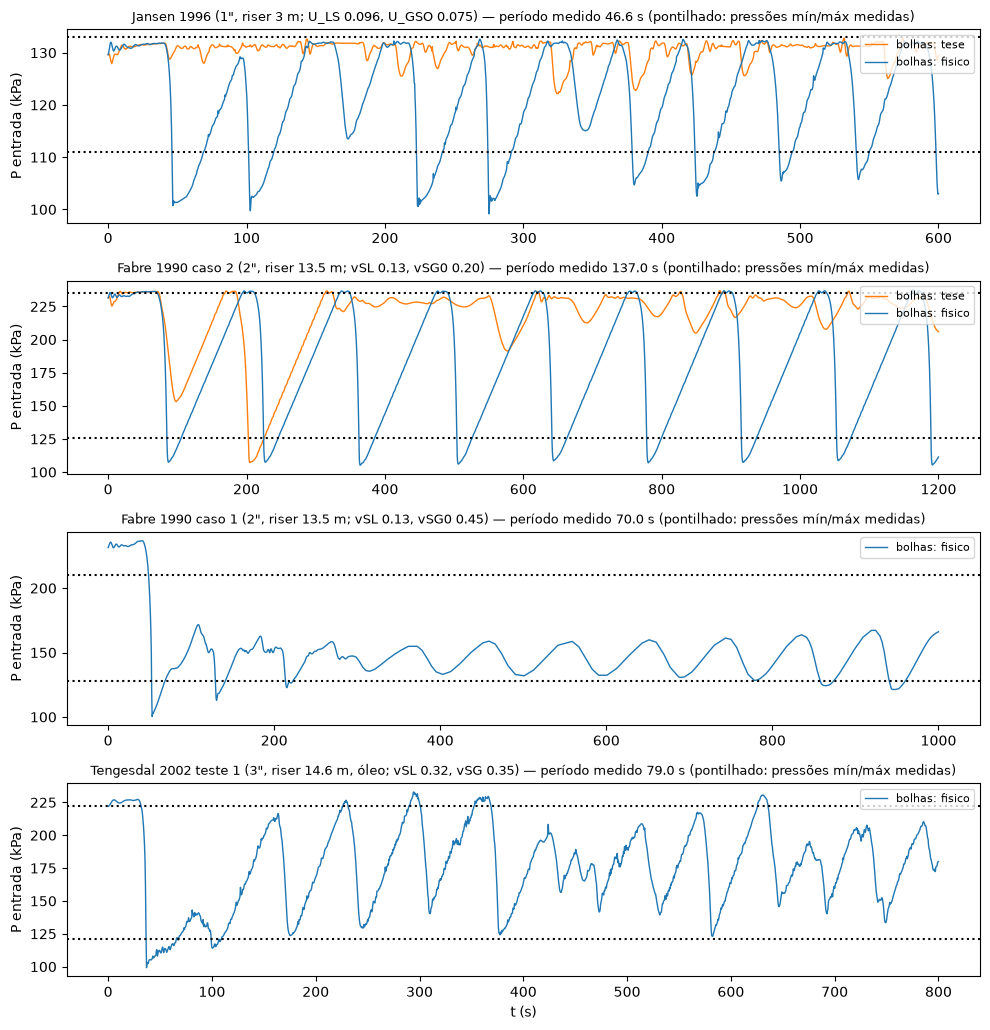

In [34]:
if runs_lab:
    keys = [k for k in LAB_REF if any(kk[0] == k for kk in runs_lab)]
    fig, axs = plt.subplots(len(keys), 1, figsize=(10, 2.6 * len(keys)), squeeze=False)
    for ax, key in zip(axs[:, 0], keys):
        for closure, c in (("tese", "C1"), ("fisico", "C0")):
            if (key, closure) in runs_lab:
                r = runs_lab[(key, closure)]; ax.plot(r["T"], r["P"], c, lw=1, label=f"bolhas: {closure}")
        ax.axhline(LAB_REF[key]["P_min"], ls=":", c="k"); ax.axhline(LAB_REF[key]["P_max"], ls=":", c="k")
        ax.set_title(f"{LAB_REF[key]['nome']} — período medido {LAB_REF[key]['periodo']} s (pontilhado: pressões mín/máx medidas)", fontsize=9)
        ax.set_ylabel("P entrada (kPa)"); ax.legend(fontsize=8, loc="upper right")
    axs[-1, 0].set_xlabel("t (s)"); fig.tight_layout()

### Arraste de gotas: é relevante?

A tese não tem arraste de gotas. Antes de modelar, a fração arrastada de Ishii &
Mishima (1989), E = tanh(7.25e−7·We^1.25·Re_L^0.25), é avaliada em pós-processamento nas
células do riser das trajetórias gravadas. Só é apreciável nos poucos segundos do pico de
gás do blowdown dos casos de linha longa (vSG ≈ 28 m/s no topo); o líquido produzido
nesses instantes é 1–5 % do total. Não se justifica um campo de gotas para estes casos.

In [35]:
def ishii_E(vSL, vSG, rhoL, rhoG, muL, sigma, D_):
    We = rhoG * vSG**2 * D_ / sigma * np.cbrt(np.abs(rhoL - rhoG) / rhoG); ReL = rhoL * np.abs(vSL) * D_ / muL
    return np.tanh(7.25e-7 * np.maximum(We, 0) ** 1.25 * np.maximum(ReL, 1e-9) ** 0.25)


runs_ent = {}
for tag, fname in (("caso base, regras físicas", "severe_slug_blocked_conservative_arc_tol_hv_vm_lv.npz"),
                   ("caso base + 500 m de linha de entrada", "severe_slug_blocked_conservative_arc_tol_lh1_500.npz"),
                   ("linha de 1000 m, 2 bar, bolhas + regras", "severe_slug_blocked_conservative_arc_boe_bub_rules.npz"),
                   ("linha de 1000 m, 2 bar, vSG = 0.29", "severe_slug_blocked_conservative_arc_scan_P2_g02.npz")):
    f = os.path.join(os.path.dirname(DATA), fname)
    if not os.path.exists(f):
        print("trajetória não encontrada:", f); continue
    runs_ent[tag] = load_blocked_run(f)
print(f"{'caso':42s} {'riser > 90 % gás':>16s} {'E > 0.1':>8s} {'E máx':>6s} {'vSG máx':>8s} {'produção com E_topo > 0.1':>26s}")
for tag, r in runs_ent.items():
    th_ = np.rad2deg(r["model"].pipes[0].scheme.theta_nodes); riser_ = np.flatnonzero(th_ > 80); T_ = r["T"]
    aG_ = r["p"]["out"]["alphaG"][riser_]; vSL_ = r["p"]["out"]["velocidadeSL"][riser_]; vSG_ = r["p"]["out"]["velocidadeSG"][riser_]; P_ = r["p"]["out"]["P_bar"][riser_] * 1e5
    E_ = ishii_E(vSL_, vSG_, fluid.rhoL0, fluid.rhoG(P_), fluid.muL, fluid.sigma, D); ann_ = aG_ > 0.9
    qo = r["p"]["out"]["qL"][-1]; frac = np.trapezoid(np.where(E_[-1] > 0.1, qo, 0), T_) / np.trapezoid(qo, T_)
    print(f"{tag:42s} {ann_.mean():16.1%} {np.mean(E_[ann_] > 0.1) if ann_.any() else 0:8.1%} {E_.max():6.2f} {vSG_.max():6.1f} m/s {frac:26.1%}")

caso                                       riser > 90 % gás  E > 0.1  E máx  vSG máx  produção com E_topo > 0.1
caso base, regras físicas                             21.4%     0.0%   0.12    9.3 m/s                       0.0%
caso base + 500 m de linha de entrada                 47.4%     0.1%   0.16   11.1 m/s                       5.0%
linha de 1000 m, 2 bar, bolhas + regras               11.2%     1.0%   0.56   28.9 m/s                       1.1%
linha de 1000 m, 2 bar, vSG = 0.29                    15.7%     0.5%   0.61   27.4 m/s                       1.5%
